# Análisis factorial múltiple (MFA) con datos reales: ejes, planos y clusters de países

**Perfil:** Cuantitativo y ciencia de datos  
**Datos:** indicadores públicos del Banco Mundial (licencia CC BY 4.0), valor más reciente disponible entre 2015 y 2022 para cada país (archivos en `datos/`).

## Pregunta que guía el notebook

Los países se describen con indicadores de **cinco temas** (economía, salud, educación y digital, sociedad, ambiente y energía). Un ACP común dejaría que el grupo con más variables o más correlación interna domine los ejes. El **análisis factorial múltiple** equilibra los grupos y permite ver, para cada país, cómo lo "ve" cada tema. ¿Qué ejes resumen el desarrollo de los países? ¿Qué grupos de países (clusters) aparecen? ¿Qué tan **robustos** son los ejes y los clusters a las decisiones del analista (transformaciones, imputación, pesos, qué grupo se incluye)?

## Recorrido

1. **Datos reales** del Banco Mundial (26 indicadores, 217 economías): cobertura, años, asimetrías y datos faltantes.
2. **Tratamiento:** transformaciones por asimetría e **imputación por ACP iterativo** con rango elegido por validación.
3. **Motor MFA propio**, validado con identidades matemáticas y con un mundo sintético de estructura conocida.
4. **Un ACP por grupo**, coeficientes $L_g$ y $RV$ entre grupos con prueba de permutación.
5. **MFA:** autovalores, cuántos ejes retener (bastón roto y análisis paralelo), círculos de correlación, contribución de los grupos.
6. **Planos de individuos**, puntos parciales, variables cualitativas suplementarias (ingreso, región) y elipses por *bootstrap*.
7. **Clusters** (Ward + consolidación k-means, estilo HCPC): elección de $k$, estabilidad por *bootstrap*, descripción y validación externa.
8. **Robustez:** MFA frente a ACP, con y sin transformaciones, imputación frente a casos completos, quitar un grupo a la vez, un país a la vez.
9. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats, linalg
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture
from matplotlib.patches import Ellipse
from pathlib import Path
import itertools

## 2. Los datos reales

26 indicadores en 5 grupos. Para cada país se toma el **último valor disponible entre 2015 y 2022** (la gran mayoría de 2022; unos pocos de años anteriores). Es una mezcla de años: se documenta y se evalúa su efecto más adelante. Se descartan las agregaciones regionales (solo economías).

In [2]:
DIR = Path("datos")
largo = pd.read_csv(DIR / "indicadores_wb_largo.csv"); meta = pd.read_csv(DIR / "paises_meta.csv").set_index("iso3"); meta["region"] = meta["region"].str.strip(); meta["ingreso"] = meta["ingreso"].str.strip()
largo = largo[largo.iso3.isin(meta.index)]
GRUPOS_ORDEN = ["economia", "salud", "educacion_digital", "sociedad", "ambiente_energia"]
grupos = {g: largo[largo.grupo == g].variable.drop_duplicates().tolist() for g in GRUPOS_ORDEN}
W = largo.pivot(index="iso3", columns="variable", values="valor")[sum(grupos.values(), [])]
anio = largo.pivot(index="iso3", columns="variable", values="anio")
print(f"{W.shape[0]} economias x {W.shape[1]} indicadores; grupos: " + ", ".join(f"{g} ({len(v)})" for g, v in grupos.items()))
cob = W.notna().mean()
print(f"Cobertura por indicador: min {cob.min():.0%} ({cob.idxmin()}), mediana {cob.median():.0%}")
print(f"Anio del dato: " + ", ".join(f"{a}: {n}" for a, n in largo.anio.value_counts().sort_index().tail(5).items()) + f"; anteriores a 2022: {(largo.anio < 2022).sum()} de {len(largo)} observaciones ({(largo.anio < 2022).mean():.1%})")
desc = W.describe().T[["count", "mean", "50%", "std", "min", "max"]].assign(asimetria=W.skew()); desc.round(2)

217 economias x 26 indicadores; grupos: economia (6), salud (5), educacion_digital (5), sociedad (5), ambiente_energia (5)
Cobertura por indicador: min 69% (electricidad_pc), mediana 93%
Anio del dato: 2018: 22, 2019: 24, 2020: 28, 2021: 194, 2022: 4828; anteriores a 2022: 337 de 5165 observaciones (6.5%)


,count,mean,50%,std,min,max,asimetria
variable,,,,,,,
pib_pc_ppa,199.0000,"26,809.4800","16,932.7700","26,569.0700","1,028.1100","134,828.0000",1.5600
agricultura_pib,202.0000,10.1500,6.6600,10.3500,0.0100,42.8500,1.2200
industria_pib,205.0000,26.0600,24.2200,13.5300,2.3900,76.8400,1.0900
comercio_pib,188.0000,100.1700,88.0500,63.0300,2.7000,412.1800,2.1600
inflacion,190.0000,13.5000,7.9300,26.0600,-6.6900,254.9500,6.4100
inversion_pib,179.0000,24.3300,24.2000,8.9800,-10.6000,55.7800,0.0200
esperanza_vida,217.0000,73.1100,74.2100,7.9400,18.8200,85.7500,-1.7400
mortalidad_infantil,196.0000,20.2700,12.9500,22.2300,1.3000,206.8000,3.6300
gasto_salud_pib,193.0000,6.8300,6.5700,3.3600,1.7700,23.0900,1.4600


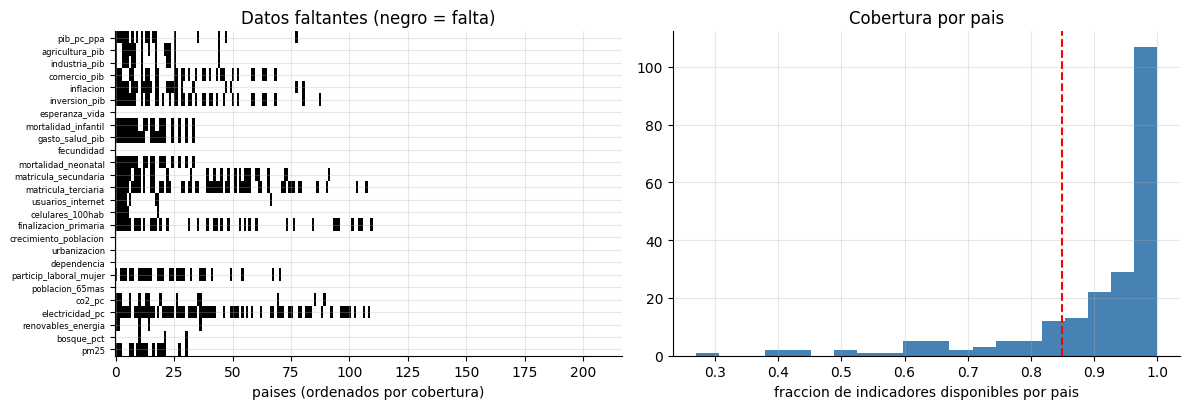

Lectura:
  107 paises tienen los 26 indicadores; 171 tienen al menos el 85%; 5 tienen menos de la mitad.
  Los paises con baja cobertura se concentran en High income (31 de 46) y en la region Latin America & Caribbean (16): la falta de datos NO es aleatoria, lo que obliga a probar la sensibilidad de la imputacion.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
orden_f = W.notna().mean(axis=1).sort_values().index
im = ax[0].imshow(W.loc[orden_f].isna().values.T, aspect="auto", cmap="Greys", interpolation="nearest"); ax[0].set_yticks(range(W.shape[1])); ax[0].set_yticklabels(W.columns, fontsize=6); ax[0].set_xlabel("paises (ordenados por cobertura)"); ax[0].set_title("Datos faltantes (negro = falta)")
ax[1].hist(W.notna().mean(axis=1), bins=20, color="steelblue"); ax[1].axvline(0.85, c="r", ls="--"); ax[1].set_xlabel("fraccion de indicadores disponibles por pais"); ax[1].set_title("Cobertura por pais")
plt.tight_layout(); plt.show()
cp = W.notna().mean(axis=1)
print("Lectura:")
print(f"  {int((cp == 1).sum())} paises tienen los 26 indicadores; {int((cp >= 0.85).sum())} tienen al menos el 85%; {int((cp < 0.5).sum())} tienen menos de la mitad.")
sin = meta.loc[cp[cp < 0.85].index]
print(f"  Los paises con baja cobertura se concentran en {sin.ingreso.value_counts().idxmax()} ({sin.ingreso.value_counts().max()} de {len(sin)}) y en la region {sin.region.value_counts().idxmax()} ({sin.region.value_counts().max()}): la falta de datos NO es aleatoria, lo que obliga a probar la sensibilidad de la imputacion.")

## 3. Tratamiento: asimetría, transformaciones, faltantes

**Transformaciones.** Un ACP/MFA se basa en correlaciones lineales; las variables con colas muy pesadas (PIB, CO₂, electricidad) hacen que unos pocos países dominen. Regla fijada *antes* de ver los ejes: si la asimetría $|g_1|>1$ y la variable es positiva, se aplica $\log(1+x)$; si puede ser negativa (inflación), $\operatorname{asinh}$. Después se estandariza.

**Faltantes.** Se conservan los países con ≥ 85 % de indicadores (los demás tendrían imputadas demasiadas celdas). Los valores faltantes se imputan con **ACP iterativo** (SVD de rango $r$ sobre la tabla estandarizada, se reemplazan los faltantes por la reconstrucción y se repite hasta converger). El rango $r$ se elige por **validación**: se ocultan al azar 10 % de las celdas observadas y se mide el error de recuperarlas.

In [4]:
asim = W.skew(); a_log = [c for c in W.columns if abs(asim[c]) > 1 and W[c].min() >= 0]; a_asinh = [c for c in W.columns if abs(asim[c]) > 1 and W[c].min() < 0]
def transformar(Wd, usar=True):
    T = Wd.copy()
    if not usar: return T
    for c in a_log: T[c] = np.log1p(Wd[c])
    for c in a_asinh: T[c] = np.arcsinh(Wd[c])
    return T
T = transformar(W)
cmp = pd.DataFrame({"asimetria_antes": asim, "asimetria_despues": T.skew(), "transformacion": ["log1p" if c in a_log else "asinh" if c in a_asinh else "-" for c in W.columns]})
print(f"Transformadas: {len(a_log)} con log1p, {len(a_asinh)} con asinh")
cmp[cmp.transformacion != "-"].round(2)

Transformadas: 11 con log1p, 1 con asinh


,asimetria_antes,asimetria_despues,transformacion
variable,,,
pib_pc_ppa,1.5600,-0.3100,log1p
agricultura_pib,1.2200,-0.0800,log1p
industria_pib,1.0900,-0.5500,log1p
comercio_pib,2.1600,-0.5900,log1p
inflacion,6.4100,-0.4700,asinh
esperanza_vida,-1.7400,-4.7500,log1p
mortalidad_infantil,3.6300,0.0400,log1p
gasto_salud_pib,1.4600,0.0800,log1p
fecundidad,1.1400,0.5700,log1p


In [5]:
def imputar_acp(X, r, iters=500, tol=1e-7):
    # X: matriz con NaN. ACP iterativo de rango r sobre la tabla estandarizada; devuelve (X completa, Z completa).
    # Los valores observados NO se modifican: solo se reemplazan las celdas faltantes por la reconstruccion de rango r.
    M = np.isnan(X); mu = np.nanmean(X, axis=0); sd = np.nanstd(X, axis=0); Z = (X - mu) / sd; Zc = np.where(M, 0.0, Z)
    for _ in range(iters):
        m2 = Zc.mean(axis=0); U, s, Vt = np.linalg.svd(Zc - m2, full_matrices=False); R = (U[:, :r] * s[:r]) @ Vt[:r] + m2; Zn = np.where(M, R, Z)
        if np.abs(Zn - Zc).max() < tol: Zc = Zn; break
        Zc = Zn
    return Zc * sd + mu, Zc

Tk = T.loc[cp >= 0.85]; X = Tk.values
rg = np.random.default_rng(SEED); obs = np.argwhere(~np.isnan(X)); filas = []
for r in (1, 2, 3, 4, 5, 6, 8):
    errs = []
    for rep in range(4):
        idx = obs[rg.choice(len(obs), int(0.10 * len(obs)), replace=False)]; Xm = X.copy(); Xm[idx[:, 0], idx[:, 1]] = np.nan
        _, Zc = imputar_acp(Xm, r); mu = np.nanmean(Xm, axis=0); sd = np.nanstd(Xm, axis=0); rec = Zc * sd + mu
        errs.append(np.sqrt(np.mean(((rec[idx[:, 0], idx[:, 1]] - X[idx[:, 0], idx[:, 1]]) / np.nanstd(X, axis=0)[idx[:, 1]]) ** 2)))
    filas.append({"rango_r": r, "RMSE_estandarizado": np.mean(errs), "sd": np.std(errs)})
cvimp = pd.DataFrame(filas).set_index("rango_r"); R_IMP = int(cvimp.RMSE_estandarizado.idxmin())
print(f"Rango elegido por validacion: r = {R_IMP}"); cvimp.round(4)

Rango elegido por validacion: r = 2


,RMSE_estandarizado,sd
rango_r,,
1,0.7927,0.0556
2,0.7216,0.0518
3,0.7418,0.0295
4,0.8010,0.0352
5,1.3272,0.7220
6,1.0727,0.2003
8,2.1058,0.3041


In [6]:
Ximp, _ = imputar_acp(Tk.values, R_IMP)
D = pd.DataFrame(Ximp, index=Tk.index, columns=Tk.columns)                               # tabla completa imputada (escala transformada)
faltaba = Tk.isna().values
print(f"Paises analizados: {len(D)} ({len(W) - len(D)} excluidos por cobertura < 85%); celdas imputadas: {faltaba.sum()} de {faltaba.size} ({faltaba.mean():.1%})")
print("Valores observados no cambian:", np.allclose(D.values[~faltaba], Tk.values[~faltaba]))
print("Paises excluidos (muestra):", ", ".join(meta.loc[W.index.difference(D.index), "pais"].head(8)) + " ...")

Paises analizados: 171 (46 excluidos por cobertura < 85%); celdas imputadas: 112 de 4446 (2.5%)
Valores observados no cambian: True
Paises excluidos (muestra): Aruba, Andorra, American Samoa, Antigua and Barbuda, Bermuda, Channel Islands, Curacao, Cayman Islands ...


In [7]:
print("Lectura:")
print(f"  El rango r={R_IMP} reconstruye las celdas ocultas con un error de {cvimp.loc[R_IMP, 'RMSE_estandarizado']:.2f} desviaciones estandar (referencia: imputar la media da 1.00 por construccion); con r mayor el error {'sube' if cvimp.RMSE_estandarizado.iloc[-1] > cvimp.loc[R_IMP, 'RMSE_estandarizado'] else 'no baja'} por sobreajuste.")
print(f"  Solo {faltaba.mean():.1%} de las celdas son imputadas, pero se concentran en pocos paises y variables ({', '.join(Tk.columns[faltaba.mean(axis=0).argsort()[::-1][:3]])}).")

Lectura:
  El rango r=2 reconstruye las celdas ocultas con un error de 0.72 desviaciones estandar (referencia: imputar la media da 1.00 por construccion); con r mayor el error sube por sobreajuste.
  Solo 2.5% de las celdas son imputadas, pero se concentran en pocos paises y variables (electricidad_pc, matricula_terciaria, finalizacion_primaria).


## 4. El motor MFA, paso a paso, y su validación

**Algoritmo.** (1) Estandarizar cada variable (ACP normado). (2) Para cada grupo $j$, hacer un ACP y guardar su primer autovalor $\lambda_1^{j}$. (3) Dividir las variables del grupo por $\sqrt{\lambda_1^{j}}$: ningún grupo puede aportar más de 1 al primer eje. (4) ACP global de la tabla ponderada: autovalores $\lambda_s$ (cada uno $\le G$, el número de grupos) y coordenadas $F$ de los individuos. (5) **Puntos parciales:** la coordenada del país $i$ vista solo por el grupo $j$ es $G\cdot Z_j V_s$; el promedio de los $G$ parciales es la coordenada global. (6) **Contribución de un grupo a un eje** = suma de los cuadrados de las cargas de sus variables (suma 1 entre grupos).

Antes de usarlo con datos reales se verifica con identidades exactas y con un mundo sintético donde la estructura se conoce.

In [8]:
def mfa(df, grupos, ncomp=None):
    n = len(df); w = np.full(n, 1 / n)
    Z, peso_g, lam1, acp_g, cols, gidx, Zs = [], {}, {}, {}, [], [], []
    for g, vs in grupos.items():
        Xg = df[vs].values.astype(float); Xg = (Xg - w @ Xg) / np.sqrt(w @ (Xg - w @ Xg) ** 2); Zs.append(Xg)
        U, s, Vt = np.linalg.svd(np.sqrt(w)[:, None] * Xg, full_matrices=False); lam = s ** 2
        lam1[g] = lam[0]; peso_g[g] = 1 / lam[0]; acp_g[g] = {"coord": (U * s) / np.sqrt(w)[:, None], "eig": lam, "Vt": Vt}
        Z.append(Xg * np.sqrt(peso_g[g])); cols += vs; gidx += [g] * len(vs)
    Z = np.hstack(Z); Zs = np.hstack(Zs); gidx = np.array(gidx)
    U, s, Vt = np.linalg.svd(np.sqrt(w)[:, None] * Z, full_matrices=False); lam = s ** 2
    signo = np.sign(Vt[np.arange(len(s)), np.abs(Vt).argmax(axis=1)]); U = U * signo; Vt = Vt * signo[:, None]          # signo determinista: la variable de mayor carga es positiva
    k = len(s) if ncomp is None else ncomp; nom = [f"F{i + 1}" for i in range(k)]
    F = (U * s)[:, :k] / np.sqrt(w)[:, None]
    parcial = {}
    for g in grupos:
        Zg = np.zeros_like(Z); Zg[:, gidx == g] = Z[:, gidx == g]; parcial[g] = len(grupos) * (Zg @ Vt.T[:, :k])
    corr = (Zs * w[:, None]).T @ (F / np.sqrt(lam[:k]))
    carga = Vt.T[:, :k]; contrib_g = pd.DataFrame({g: (carga[gidx == g] ** 2).sum(axis=0) for g in grupos}, index=nom).T
    contrib_v = pd.DataFrame(carga ** 2, index=cols, columns=nom)
    return {"F": F, "parcial": parcial, "eig": lam, "corr": pd.DataFrame(corr, index=cols, columns=nom), "contrib_g": contrib_g, "contrib_v": contrib_v, "lam1": lam1,
            "peso_g": peso_g, "acp_g": acp_g, "Z": Z, "gidx": gidx, "cols": cols, "Vt": Vt, "w": w, "k": k, "index": df.index, "grupos": grupos}

def acp(df, ncomp=None):
    # ACP normado simple (un solo 'grupo' con todas las variables y sin balanceo entre grupos)
    return mfa(df, {"todo": list(df.columns)}, ncomp)

# ---- Validacion 1: identidades exactas con datos reales
M = mfa(D, grupos); n_, p_ = D.shape
print("Autovalores >= 0 y decrecientes:", (np.diff(M["eig"]) <= 1e-12).all())
print("Primer autovalor ponderado de cada grupo = 1:", {g: round(M["lam1"][g] * M["peso_g"][g], 10) for g in grupos})
print("Promedio de puntos parciales = coordenada global (error max):", float(np.abs(sum(M["parcial"].values()) / len(grupos) - M["F"]).max()))
print("Ejes ortogonales: max |<F_s,F_t>|/n =", float(np.abs((M["F"].T @ M["F"]) / n_ - np.diag(M["eig"])).max()))
print("Inercia total = suma_j sum_s lambda_s^j / lambda_1^j:", round(M["eig"].sum(), 8), "=", round(sum(M["acp_g"][g]["eig"].sum() / M["lam1"][g] for g in grupos), 8))
print("Contribuciones de grupos suman 1 en cada eje:", np.allclose(M["contrib_g"].sum(axis=0), 1))
print("Todos los autovalores <= G =", len(grupos), ":", bool((M["eig"] <= len(grupos) + 1e-9).all()))

Autovalores >= 0 y decrecientes: True
Primer autovalor ponderado de cada grupo = 1: {'economia': np.float64(1.0), 'salud': np.float64(1.0), 'educacion_digital': np.float64(1.0), 'sociedad': np.float64(1.0), 'ambiente_energia': np.float64(1.0)}
Promedio de puntos parciales = coordenada global (error max): 4.285460875053104e-14
Ejes ortogonales: max |<F_s,F_t>|/n = 1.7763568394002505e-15
Inercia total = suma_j sum_s lambda_s^j / lambda_1^j: 9.67935616 = 9.67935616
Contribuciones de grupos suman 1 en cada eje: True
Todos los autovalores <= G = 5 : True


In [9]:
# ---- Validacion 2: con un solo grupo, MFA = ACP normado = autovalores de la matriz de correlaciones
M1 = acp(D); ev_corr = np.sort(np.linalg.eigvalsh(np.corrcoef(D.values.T)))[::-1]
print("Un grupo: autovalores del motor vs matriz de correlaciones (max dif):", float(np.abs(M1["eig"] * M1["lam1"]["todo"] - ev_corr).max()))

# ---- Validacion 3: mundo sintetico con estructura conocida (3 grupos de 'indicadores', 2 factores latentes, 3 clusters de individuos)
def mundo_sintetico(seed, n=240, ruido=0.6):
    rg = np.random.default_rng(seed); lab = rg.integers(0, 3, n); centros = np.array([[-2.0, 0.0], [1.5, 2.0], [1.0, -2.0]])
    f = centros[lab] + 0.7 * rg.standard_normal((n, 2))
    # grupo A: 10 variables casi duplicadas del factor 1 (dominarian un ACP); B: 4 del factor 2; C: 4 mezcla de ambos
    A = {f"A{i}": f[:, 0] + 0.3 * rg.standard_normal(n) for i in range(10)}
    B = {f"B{i}": f[:, 1] + ruido * rg.standard_normal(n) for i in range(4)}
    Cc = {f"C{i}": 0.7 * f[:, 0] + 0.7 * f[:, 1] + ruido * rg.standard_normal(n) for i in range(4)}
    return pd.DataFrame({**A, **B, **Cc}), lab, {"A": list(A), "B": list(B), "C": list(Cc)}
Ds, lab_s, gr_s = mundo_sintetico(1)
Ms = mfa(Ds, gr_s); Ps = acp(Ds)
cg_pca = pd.DataFrame({g: (Ps["Vt"].T[:, :2][[Ds.columns.get_loc(c) for c in gr_s[g]]] ** 2).sum(axis=0) for g in gr_s}, index=["F1", "F2"]).T
print("\nMundo sintetico (grupo A = 10 variables redundantes del factor 1):")
print("  contribucion de grupos al eje 1  - ACP: ", cg_pca["F1"].round(2).to_dict(), " | MFA:", Ms["contrib_g"]["F1"].round(2).to_dict())
print("  contribucion de grupos al eje 2  - ACP: ", cg_pca["F2"].round(2).to_dict(), " | MFA:", Ms["contrib_g"]["F2"].round(2).to_dict())
ari_s = {}
for nombre, MM in (("MFA", Ms), ("ACP", Ps)):
    km = KMeans(3, n_init=20, random_state=0).fit(MM["F"][:, :2]); ari_s[nombre] = adjusted_rand_score(lab_s, km.labels_)
print("  ARI de los clusters recuperados con 2 ejes:", {k: round(v, 3) for k, v in ari_s.items()})

Un grupo: autovalores del motor vs matriz de correlaciones (max dif): 1.4210854715202004e-14

Mundo sintetico (grupo A = 10 variables redundantes del factor 1):
  contribucion de grupos al eje 1  - ACP:  {'A': 0.74, 'B': 0.03, 'C': 0.23}  | MFA: {'A': 0.24, 'B': 0.27, 'C': 0.49}
  contribucion de grupos al eje 2  - ACP:  {'A': 0.16, 'B': 0.66, 'C': 0.17}  | MFA: {'A': 0.52, 'B': 0.47, 'C': 0.0}


  ARI de los clusters recuperados con 2 ejes: {'MFA': 0.987, 'ACP': 0.975}


In [10]:
print("Lectura:")
print(f"  Las identidades se cumplen al nivel de error numerico, tambien con los datos reales ({n_} paises x {p_} variables).")
print(f"  En el mundo sintetico el ACP deja que el grupo A (10 variables redundantes) aporte {cg_pca.loc['A', 'F1']:.0%} del eje 1; el MFA lo reduce a {Ms['contrib_g'].loc['A', 'F1']:.0%} y reparte el resto entre B y C. Los clusters verdaderos se recuperan con ARI {ari_s['MFA']:.2f} (MFA) frente a {ari_s['ACP']:.2f} (ACP).")

Lectura:
  Las identidades se cumplen al nivel de error numerico, tambien con los datos reales (171 paises x 26 variables).
  En el mundo sintetico el ACP deja que el grupo A (10 variables redundantes) aporte 74% del eje 1; el MFA lo reduce a 24% y reparte el resto entre B y C. Los clusters verdaderos se recuperan con ARI 0.99 (MFA) frente a 0.97 (ACP).


## 5. Un ACP por grupo, $L_g$ y $RV$ entre grupos

Antes del análisis global, cada tema se estudia por separado: su primer autovalor $\lambda_1^j$ (cuanta estructura tiene el grupo en una sola dirección) y la correlación entre grupos. Con $X_j$ la tabla estandarizada del grupo $j$ y $D$ los pesos de fila, $\operatorname{tr}(W_jDW_kD)=\|X_j^\top D X_k\|_F^2$ (con $W_j=X_jX_j^\top$). Entonces
$$L_g(j,k)=\frac{\|X_j^\top DX_k\|_F^2}{\lambda_1^j\lambda_1^k},\qquad RV(j,k)=\frac{\|X_j^\top DX_k\|_F^2}{\|X_j^\top DX_j\|_F\,\|X_k^\top DX_k\|_F}.$$
$L_g(j,j)$ mide la **dimensionalidad** del grupo (1 = una sola dirección) y $RV\in[0,1]$ la similitud entre las configuraciones de países de dos grupos. La significancia del $RV$ se evalúa con una **prueba de permutación** (se barajan las filas de un grupo).

In [11]:
def estd(X): return (X - X.mean(axis=0)) / X.std(axis=0)
XG = {g: estd(D[vs].values) for g, vs in grupos.items()}; nn = len(D)
def cruz(A, B): return np.linalg.norm(A.T @ B / nn, "fro") ** 2
l1 = {g: np.linalg.eigvalsh(XG[g].T @ XG[g] / nn)[-1] for g in grupos}
Lg = pd.DataFrame({k: {j: cruz(XG[j], XG[k]) / (l1[j] * l1[k]) for j in grupos} for k in grupos})
RV = pd.DataFrame({k: {j: cruz(XG[j], XG[k]) / np.sqrt(cruz(XG[j], XG[j]) * cruz(XG[k], XG[k])) for j in grupos} for k in grupos})
rg = np.random.default_rng(SEED); NP = 2000; pval = pd.DataFrame(np.nan, index=list(grupos), columns=list(grupos))
for j, k in itertools.combinations(list(grupos), 2):
    obs_ = RV.loc[j, k]; perm = np.array([cruz(XG[j], XG[k][rg.permutation(nn)]) / np.sqrt(cruz(XG[j], XG[j]) * cruz(XG[k], XG[k])) for _ in range(NP)])
    pval.loc[j, k] = pval.loc[k, j] = (1 + (perm >= obs_).sum()) / (NP + 1)
inercia1 = pd.DataFrame({g: {"n_variables": len(grupos[g]), "lambda_1": l1[g], "% inercia eje 1": l1[g] / len(grupos[g]), "lambda_2": np.sort(np.linalg.eigvalsh(XG[g].T @ XG[g] / nn))[-2], "Lg(j,j)": Lg.loc[g, g]} for g in grupos}).T
print(inercia1.round(3).to_string()); print("\nRV entre grupos:"); print(RV.round(3).to_string()); print("\np-valor de permutacion del RV:"); print(pval.round(4).to_string())

                   n_variables  lambda_1  % inercia eje 1  lambda_2  Lg(j,j)
economia                6.0000    2.3620           0.3940    1.2700   1.6100
salud                   5.0000    3.5540           0.7110    0.8660   1.0710
educacion_digital       5.0000    3.5250           0.7050    0.6600   1.0570
sociedad                5.0000    2.1440           0.4290    1.1280   1.5390
ambiente_energia        5.0000    2.5230           0.5050    1.3470   1.3710

RV entre grupos:
                   economia  salud  educacion_digital  sociedad  ambiente_energia
economia             1.0000 0.5040             0.5130    0.4440            0.5160
salud                0.5040 1.0000             0.7550    0.6490            0.5940
educacion_digital    0.5130 0.7550             1.0000    0.6190            0.6270
sociedad             0.4440 0.6490             0.6190    1.0000            0.5580
ambiente_energia     0.5160 0.5940             0.6270    0.5580            1.0000

p-valor de permutacion del 

In [12]:
rv_off = RV.values[np.triu_indices(5, 1)]; ir, ic = np.unravel_index(np.argmax(np.where(np.eye(5, dtype=bool), -1, RV.values)), RV.shape); jr, jc = np.unravel_index(np.argmin(np.where(np.eye(5, dtype=bool), 9, RV.values)), RV.shape)
print("Lectura:")
print(f"  El grupo con estructura mas concentrada en un eje es {inercia1['% inercia eje 1'].idxmax()} ({inercia1['% inercia eje 1'].max():.0%} de su inercia en el primer eje); el mas multidimensional, {inercia1['% inercia eje 1'].idxmin()} ({inercia1['% inercia eje 1'].min():.0%}).")
print(f"  RV entre grupos: de {rv_off.min():.2f} a {rv_off.max():.2f}. Mas parecidos: {RV.index[ir]} y {RV.columns[ic]} ({RV.iloc[ir, ic]:.2f}); menos: {RV.index[jr]} y {RV.columns[jc]} ({RV.iloc[jr, jc]:.2f}).")
print(f"  Todos los pares son significativos con 2.000 permutaciones (max p = {np.nanmax(pval.values):.4f}): los cinco temas comparten una estructura comun de paises; vale la pena un analisis conjunto.")

Lectura:
  El grupo con estructura mas concentrada en un eje es salud (71% de su inercia en el primer eje); el mas multidimensional, economia (39%).
  RV entre grupos: de 0.44 a 0.75. Mas parecidos: salud y educacion_digital (0.75); menos: sociedad y economia (0.44).
  Todos los pares son significativos con 2.000 permutaciones (max p = 0.0005): los cinco temas comparten una estructura comun de paises; vale la pena un analisis conjunto.


## 6. El MFA: autovalores y cuántos ejes retener

Los autovalores del MFA están acotados por el número de grupos, $G=5$; el primero vale $G$ solo si todos los grupos comparten **exactamente** una dirección. Para decidir cuántos ejes retener se usan dos referencias:

- **Bastón roto:** si la inercia total se repartiera al azar entre los ejes, el eje $s$ esperaría $\frac{1}{p}\sum_{i=s}^{p}\frac1i$ de la inercia.
- **Análisis paralelo (Horn):** se **permuta cada variable por separado** (se destruye la correlación entre variables conservando las distribuciones marginales), se recalcula el MFA 300 veces y se compara cada autovalor con el percentil 95 de la nula.
- **Análisis paralelo condicional (con deflación):** el análisis de Horn compara todos los ejes con la misma nula, pero si hay un eje dominante los demás quedan "aplastados" (la inercia total es fija). Para el eje $s$ se **restan los $s-1$ primeros ejes** de la tabla ponderada, se permutan las columnas del residuo y se compara $\lambda_s$ con el percentil 95 del primer autovalor de la nula.

   autovalor  % inercia  % acumulado  baston_roto_%  P95_nula_permutacion  retener_PA  retener_baston
0     4.3670    45.1120      45.1120        14.8250                1.5710        True            True
1     1.0420    10.7650      55.8770        10.9790                1.4520       False           False
2     0.7300     7.5410      63.4180         9.0550                1.3550       False           False
3     0.4830     4.9870      68.4050         7.7730                1.2810       False           False
4     0.4230     4.3650      72.7700         6.8120                1.2180       False           False
5     0.3750     3.8720      76.6410         6.0430                1.1630       False           False
6     0.2960     3.0620      79.7030         5.4020                1.1080       False           False
7     0.2780     2.8680      82.5710         4.8520                1.0560       False           False
8     0.2650     2.7340      85.3060         4.3710                1.0110       Fa

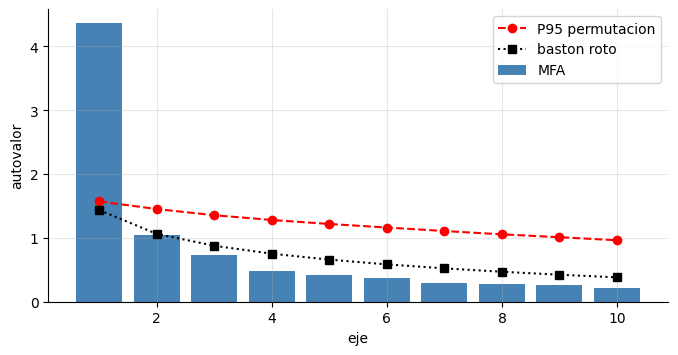

In [13]:
M = mfa(D, grupos); lam = M["eig"]; tot = lam.sum(); K = len(lam)
bastón = np.array([(1 / np.arange(s + 1, K + 1)).sum() / K for s in range(K)])
rg = np.random.default_rng(SEED); NPA = 300; nulos = np.empty((NPA, K))
for b in range(NPA):
    Dp = pd.DataFrame({c: rg.permutation(D[c].values) for c in D.columns}, index=D.index); nulos[b] = mfa(Dp, grupos)["eig"][:K]
p95 = np.percentile(nulos, 95, axis=0)
eigtab = pd.DataFrame({"autovalor": lam, "% inercia": 100 * lam / tot, "% acumulado": 100 * np.cumsum(lam) / tot, "baston_roto_%": 100 * bastón, "P95_nula_permutacion": p95}).iloc[:10]
eigtab["retener_PA"] = lam[:10] > p95[:10]; eigtab["retener_baston"] = eigtab["% inercia"] > eigtab["baston_roto_%"]
print(eigtab.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(range(1, 11), lam[:10], color="steelblue", label="MFA"); ax.plot(range(1, 11), p95[:10], "r--o", label="P95 permutacion"); ax.plot(range(1, 11), tot * bastón[:10], "k:s", label="baston roto"); ax.set_xlabel("eje"); ax.set_ylabel("autovalor"); ax.legend(); plt.show()

In [14]:
Zw = M["Z"]; wsq = np.sqrt(M["w"])[:, None]; Y = wsq * Zw; Uu, ss, Vv = np.linalg.svd(Y, full_matrices=False)
rg = np.random.default_rng(SEED + 1); cond = []
for s_ in range(1, 7):                                                 # eje s_+1, tras restar los s_ primeros
    Yr = Y - (Uu[:, :s_] * ss[:s_]) @ Vv[:s_]; nl = np.array([np.linalg.svd(Yr[:, rg.permutation(Yr.shape[1])] if False else np.column_stack([rg.permutation(Yr[:, j]) for j in range(Yr.shape[1])]), compute_uv=False)[0] ** 2 for _ in range(300)])
    cond.append({"eje": s_ + 1, "autovalor": lam[s_], "P95_condicional": np.percentile(nl, 95), "retener": lam[s_] > np.percentile(nl, 95)})
cond = pd.DataFrame(cond).set_index("eje"); print("Analisis paralelo condicional (deflacion):"); print(cond.round(3).to_string())

Analisis paralelo condicional (deflacion):
     autovalor  P95_condicional  retener
eje                                     
2       1.0420           0.6160     True
3       0.7300           0.5310     True
4       0.4830           0.4150     True
5       0.4230           0.3270     True
6       0.3750           0.2630     True
7       0.2960           0.2220     True


**Estabilidad por *bootstrap* del subespacio.** Los dos criterios de permutación dan extremos (1 eje frente a 7). Una tercera referencia, más cercana a lo que importa, es la **estabilidad**: se remuestrean los países con reemplazo 300 veces, se recalcula el MFA y se mide cuánto se parece el subespacio de los primeros $k$ ejes al original con el **menor coseno de los ángulos principales** entre ambos subespacios (1 = idénticos, 0 = ortogonales). Los ejes con autovalores casi iguales pueden rotar entre sí, así que se evalúa el *subespacio* y no cada eje. **Regla** (fijada antes de ver los resultados): se retiene el mayor $k$ con media $\ge0{,}90$ y percentil 5 $\ge0{,}75$.

In [15]:
rg = np.random.default_rng(5); BS = 300; V0 = M["Vt"].T; est = {k: [] for k in range(1, 9)}
for b in range(BS):
    idx = rg.integers(0, len(D), len(D)); Vb = mfa(D.iloc[idx], grupos)["Vt"].T
    for k in est: est[k].append(np.linalg.svd(V0[:, :k].T @ Vb[:, :k], compute_uv=False).min())
estab = pd.DataFrame({k: {"coseno_min_medio": np.mean(v), "P5": np.percentile(v, 5), "cumple_regla": np.mean(v) >= 0.90 and np.percentile(v, 5) >= 0.75} for k, v in est.items()}).T
estab.index.name = "k_ejes"; N_AXES = int(estab.index[estab.cumple_regla].max()); print(estab.round(3).to_string()); print(f"\nEjes retenidos por estabilidad: {N_AXES}")

       coseno_min_medio     P5 cumple_regla
k_ejes                                     
1                0.9965 0.9928         True
2                0.9272 0.5987        False
3                0.9263 0.8033         True
4                0.7374 0.1990        False
5                0.6770 0.1576        False
6                0.7332 0.2841        False
7                0.5078 0.0593        False
8                0.4687 0.0711        False

Ejes retenidos por estabilidad: 3


In [16]:
n_pa = int(np.argmax(~(lam > p95))); n_bs = int(np.argmax(~(100 * lam / tot > 100 * bastón)))
print("Lectura:")
print(f"  El primer eje tiene autovalor {lam[0]:.2f} de un maximo de {len(grupos)} ({lam[0] / len(grupos):.0%} de la cota): los cinco temas comparten una dimension dominante (nivel de desarrollo).")
print(f"  Inercia acumulada: 1 eje {100 * lam[0] / tot:.1f}%, 2 ejes {100 * lam[:2].sum() / tot:.1f}%, 3 ejes {100 * lam[:3].sum() / tot:.1f}%, 4 ejes {100 * lam[:4].sum() / tot:.1f}%.")
print(f"  Ejes que superan la nula de Horn: {n_pa}; el baston roto: {n_bs}; el analisis paralelo CONDICIONAL: {int(cond.retener.sum()) + 1} (los {int(cond.retener.sum())} ejes probados despues del primero lo superan). Con un eje dominante, Horn y el baston roto son conservadores (el eje 1 absorbe inercia y deja a los demas bajo la nula ingenua) y el condicional es liberal (permutar los residuos elimina toda dependencia dentro de los grupos).")
print(f"  El criterio de estabilidad por bootstrap resuelve el desacuerdo: el subespacio de los primeros {N_AXES} ejes es estable (coseno minimo medio {estab.loc[N_AXES, 'coseno_min_medio']:.2f}), el de {N_AXES + 1} ya no ({estab.loc[N_AXES + 1, 'coseno_min_medio']:.2f}). Se retienen {N_AXES} ejes; la seccion de robustez verifica que los clusters no dependen de este numero.")

Lectura:
  El primer eje tiene autovalor 4.37 de un maximo de 5 (87% de la cota): los cinco temas comparten una dimension dominante (nivel de desarrollo).
  Inercia acumulada: 1 eje 45.1%, 2 ejes 55.9%, 3 ejes 63.4%, 4 ejes 68.4%.
  Ejes que superan la nula de Horn: 1; el baston roto: 1; el analisis paralelo CONDICIONAL: 7 (los 6 ejes probados despues del primero lo superan). Con un eje dominante, Horn y el baston roto son conservadores (el eje 1 absorbe inercia y deja a los demas bajo la nula ingenua) y el condicional es liberal (permutar los residuos elimina toda dependencia dentro de los grupos).
  El criterio de estabilidad por bootstrap resuelve el desacuerdo: el subespacio de los primeros 3 ejes es estable (coseno minimo medio 0.93), el de 4 ya no (0.74). Se retienen 3 ejes; la seccion de robustez verifica que los clusters no dependen de este numero.


## 7. Variables y grupos: qué significan los ejes

El **círculo de correlaciones** muestra $\operatorname{corr}(x_v,F_s)$; las variables cercanas al borde y a un eje lo definen. Se grafican los planos 1-2 y 1-3 con las variables coloreadas por grupo. La **contribución de cada grupo** a un eje (suma 1) dice qué temas lo construyen; el **cuadrado de la coordenada de un grupo** (relación entre su nube y el eje) se lee como cuánto "ve" el eje ese grupo.

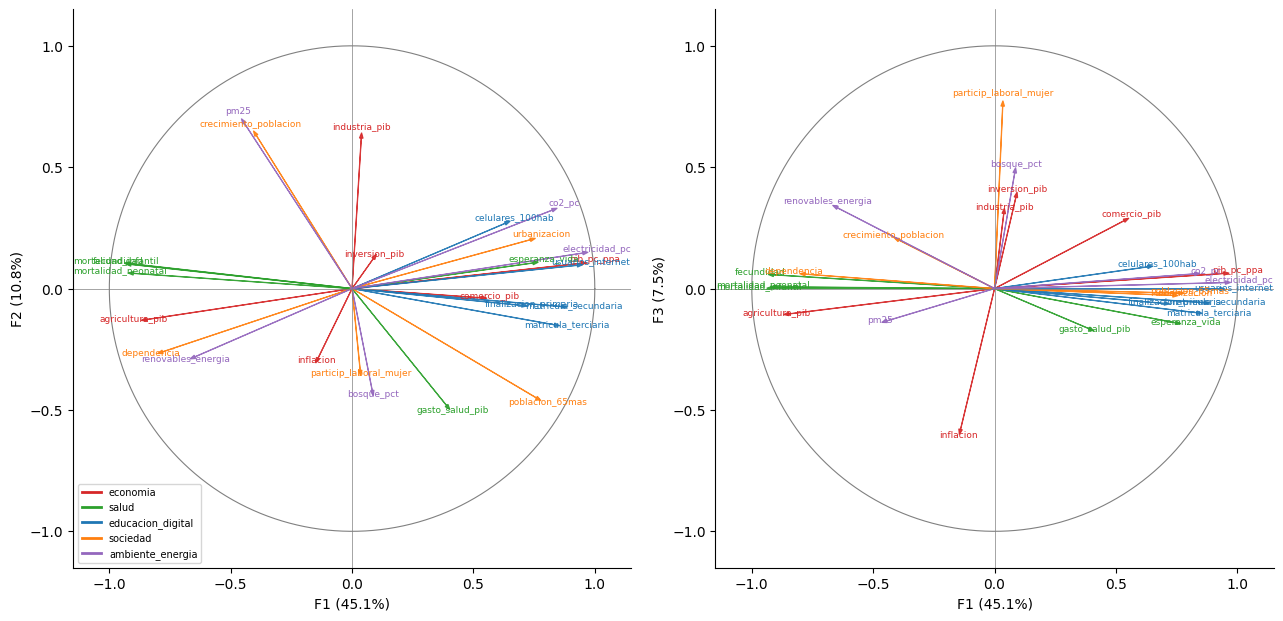

Contribucion de cada grupo a los ejes (suma 1 por eje):
                      F1     F2     F3     F4     F5
economia          0.1860 0.2070 0.3860 0.5950 0.6040
salud             0.2050 0.0720 0.0190 0.0120 0.0860
educacion_digital 0.2070 0.0310 0.0100 0.0640 0.0200
sociedad          0.2010 0.3680 0.3890 0.3010 0.1200
ambiente_energia  0.2000 0.3210 0.1950 0.0280 0.1710

F1: electricidad_pc (+0.95), pib_pc_ppa (+0.94), usuarios_internet (+0.93), mortalidad_infantil (-0.92), fecundidad (-0.91), mortalidad_neonatal (-0.90)

F2: pm25 (+0.68), crecimiento_poblacion (+0.63), industria_pib (+0.62), gasto_salud_pib (-0.48), poblacion_65mas (-0.45), bosque_pct (-0.42)

F3: particip_laboral_mujer (+0.75), inflacion (-0.58), bosque_pct (+0.48), inversion_pib (+0.38), renovables_energia (+0.33), industria_pib (+0.31)


In [17]:
COL_G = dict(zip(grupos, ["#d62728", "#2ca02c", "#1f77b4", "#ff7f0e", "#9467bd"]))
def circulo(ax, M, a, b):
    t = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(t), np.sin(t), c="gray", lw=.8); ax.axhline(0, c="gray", lw=.5); ax.axvline(0, c="gray", lw=.5)
    for v in M["cols"]:
        g = [k for k in grupos if v in grupos[k]][0]; x, y = M["corr"].loc[v, f"F{a}"], M["corr"].loc[v, f"F{b}"]
        ax.arrow(0, 0, x, y, head_width=.015, color=COL_G[g], alpha=.9, lw=.8); ax.text(x * 1.06, y * 1.06, v, fontsize=6.5, color=COL_G[g], ha="center")
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect("equal"); ax.set_xlabel(f"F{a} ({100 * M['eig'][a - 1] / M['eig'].sum():.1f}%)"); ax.set_ylabel(f"F{b} ({100 * M['eig'][b - 1] / M['eig'].sum():.1f}%)"); ax.grid(False)
fig, ax = plt.subplots(1, 2, figsize=(13, 6.3)); circulo(ax[0], M, 1, 2); circulo(ax[1], M, 1, 3)
ax[0].legend(handles=[plt.Line2D([0], [0], c=c, lw=2, label=g) for g, c in COL_G.items()], fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()
cg = M["contrib_g"].iloc[:, :5]; print("Contribucion de cada grupo a los ejes (suma 1 por eje):"); print(cg.round(3).to_string())
top = {f"F{s}": M["corr"][f"F{s}"].abs().sort_values(ascending=False).head(6) for s in (1, 2, 3)}
for s, v in top.items(): print(f"\n{s}: " + ", ".join(f"{k} ({M['corr'].loc[k, s]:+.2f})" for k in v.index))

In [18]:
print("Lectura:")
print(f"  Eje 1 ({100 * lam[0] / tot:.1f}%): lo construyen los cinco grupos de forma pareja (contribuciones entre {cg['F1'].min():.0%} y {cg['F1'].max():.0%}); correlaciona con {M['corr']['F1'].abs().idxmax()} ({M['corr'].loc[M['corr']['F1'].abs().idxmax(), 'F1']:+.2f}). Es el eje de nivel de desarrollo.")
print(f"  Eje 2 ({100 * lam[1] / tot:.1f}%): lo dominan {cg['F2'].idxmax()} ({cg['F2'].max():.0%}) y {cg['F2'].drop(cg['F2'].idxmax()).idxmax()} ({cg['F2'].drop(cg['F2'].idxmax()).max():.0%}); variables mas correlacionadas: {', '.join(M['corr']['F2'].abs().sort_values(ascending=False).index[:3])}.")
print(f"  Eje 3 ({100 * lam[2] / tot:.1f}%): lo dominan {cg['F3'].idxmax()} ({cg['F3'].max():.0%}); variables: {', '.join(M['corr']['F3'].abs().sort_values(ascending=False).index[:3])}.")

Lectura:
  Eje 1 (45.1%): lo construyen los cinco grupos de forma pareja (contribuciones entre 19% y 21%); correlaciona con electricidad_pc (+0.95). Es el eje de nivel de desarrollo.
  Eje 2 (10.8%): lo dominan sociedad (37%) y ambiente_energia (32%); variables mas correlacionadas: pm25, crecimiento_poblacion, industria_pib.
  Eje 3 (7.5%): lo dominan sociedad (39%); variables: particip_laboral_mujer, inflacion, bosque_pct.


## 8. Individuos: planos, calidad de representación y puntos parciales

La coordenada de un país es la **media de sus $G$ coordenadas parciales** (una por tema). Si los cinco puntos parciales de un país están juntos, los cinco temas lo ven igual; si se separan, hay un **perfil desbalanceado** (p. ej., rico en economía pero rezagado en salud). Se muestra: el plano 1-2 con colores por nivel de ingreso (variable *suplementaria*, que no participó en el análisis), la calidad de representación $\cos^2$ y la contribución de cada país, y los puntos parciales de países seleccionados.

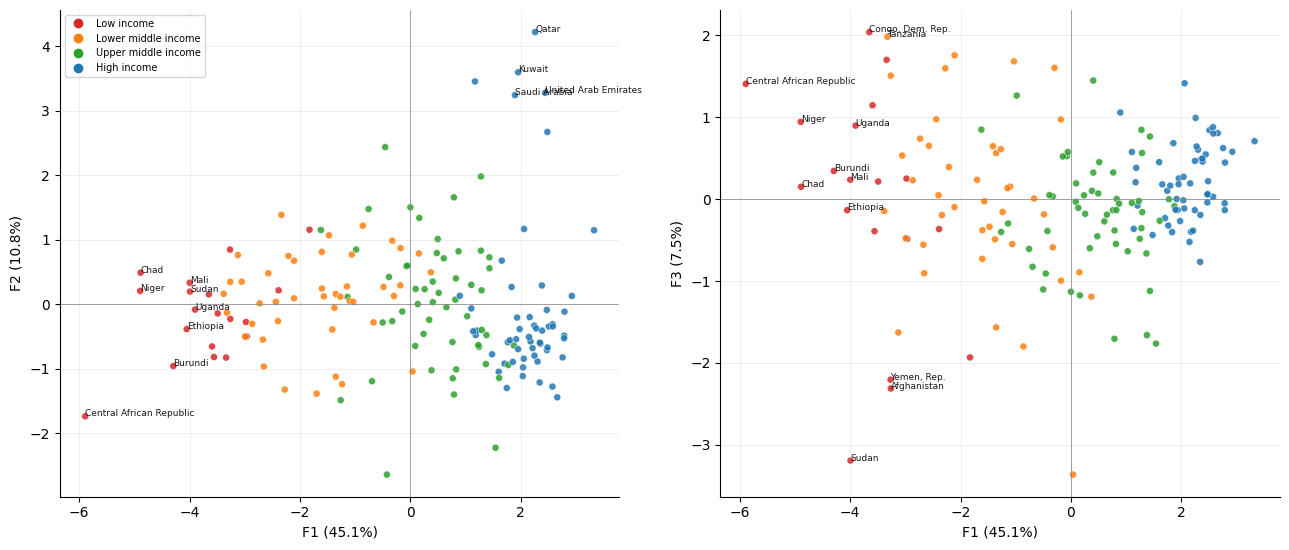

Mayores contribuciones al eje 2:
                      pais     F1     F2      F3  cos2_plano12  ctr_F1_%  ctr_F2_%
iso3                                                                              
QAT                  Qatar 2.2600 4.2200  0.9900        0.8500    0.6800    9.9800
KWT                 Kuwait 1.9500 3.5900  0.2500        0.8700    0.5100    7.2500
OMN                   Oman 1.1700 3.4500  0.2100        0.9400    0.1800    6.6900
ARE   United Arab Emirates 2.4400 3.2800  0.5500        0.8600    0.8000    6.0300
SAU           Saudi Arabia 1.9000 3.2400 -0.1300        0.8600    0.4800    5.8900
BHR                Bahrain 2.4800 2.6700  0.0600        0.8700    0.8300    4.0000

Paises mal representados en el plano 1-2 (cos2 mas bajo):
                    pais      F1      F2      F3  cos2_plano12
iso3                                                          
SUR             Suriname  0.1300  0.0000 -0.1100        0.0000
BTN               Bhutan -0.3000  0.1300  1.6000       

In [19]:
F = M["F"]; nom = meta.loc[D.index, "pais"].values; ingreso = meta.loc[D.index, "ingreso"].values; region = meta.loc[D.index, "region"].values
ORD_ING = ["Low income", "Lower middle income", "Upper middle income", "High income"]; COL_ING = dict(zip(ORD_ING, ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4"]))
cos2 = F ** 2 / (F ** 2).sum(axis=1, keepdims=True); ctr = F ** 2 / (len(D) * lam)
def plano(ax, a, b, color, etiquetar=12, alpha=.85, tam=26):
    ax.scatter(F[:, a - 1], F[:, b - 1], c=color, s=tam, alpha=alpha, edgecolor="white", lw=.4); ax.axhline(0, c="gray", lw=.5); ax.axvline(0, c="gray", lw=.5)
    d2 = F[:, a - 1] ** 2 + F[:, b - 1] ** 2
    for i in np.argsort(-d2)[:etiquetar]: ax.text(F[i, a - 1], F[i, b - 1], nom[i], fontsize=6.5, alpha=.9)
    ax.set_xlabel(f"F{a} ({100 * lam[a - 1] / tot:.1f}%)"); ax.set_ylabel(f"F{b} ({100 * lam[b - 1] / tot:.1f}%)"); ax.grid(alpha=.2)
fig, ax = plt.subplots(1, 2, figsize=(13, 5.6)); col_ing = [COL_ING[i] for i in ingreso]
plano(ax[0], 1, 2, col_ing); plano(ax[1], 1, 3, col_ing)
ax[0].legend(handles=[plt.Line2D([0], [0], marker="o", ls="", c=c, label=k) for k, c in COL_ING.items()], fontsize=7); plt.tight_layout(); plt.show()
top1 = pd.DataFrame({"pais": nom, "F1": F[:, 0], "F2": F[:, 1], "F3": F[:, 2], "cos2_plano12": cos2[:, :2].sum(axis=1), "ctr_F1_%": 100 * ctr[:, 0], "ctr_F2_%": 100 * ctr[:, 1]}, index=D.index)
print("Mayores contribuciones al eje 2:"); print(top1.sort_values("ctr_F2_%", ascending=False).head(6).round(2).to_string())
print("\nPaises mal representados en el plano 1-2 (cos2 mas bajo):"); print(top1.sort_values("cos2_plano12").head(5)[["pais", "F1", "F2", "F3", "cos2_plano12"]].round(2).to_string())

In [20]:
r1 = pd.Series(F[:, 0], index=nom); rho_ing = stats.spearmanr(F[:, 0], pd.Series(ingreso).map({k: i for i, k in enumerate(ORD_ING)}))[0]
print("Lectura:")
print(f"  El eje 1 ordena los paises casi como el nivel de ingreso (Spearman con la categoria de ingreso: {rho_ing:+.2f}); {r1.idxmin()} y {r1.nsmallest(3).index[1]} en un extremo, {r1.idxmax()} y {r1.nlargest(3).index[1]} en el otro. La variable de ingreso NO participo en el analisis.")
t10 = top1.sort_values("ctr_F2_%", ascending=False).head(10).index
print(f"  El eje 2 separa paises de un mismo nivel de desarrollo: los 10 que mas contribuyen ({', '.join(top1.loc[t10, 'pais'].head(5))}, ...) aportan {top1.loc[t10, 'ctr_F2_%'].sum():.0f}% de su inercia; {int((meta.loc[t10, 'region'].str.startswith('Middle East')).sum())} de 10 son de Medio Oriente y Norte de Africa y {int((meta.loc[t10, 'ingreso'] == 'High income').sum())} de 10 son de ingreso alto.")
print(f"  Calidad en el plano 1-2: cos2 mediano {np.median(top1.cos2_plano12):.2f}; {int((top1.cos2_plano12 < 0.3).sum())} paises quedan mal representados (<0.3) y no deben interpretarse en ese plano.")

Lectura:
  El eje 1 ordena los paises casi como el nivel de ingreso (Spearman con la categoria de ingreso: +0.92); Central African Republic y Niger en un extremo, Singapore y Korea, Rep. en el otro. La variable de ingreso NO participo en el analisis.
  El eje 2 separa paises de un mismo nivel de desarrollo: los 10 que mas contribuyen (Qatar, Kuwait, Oman, United Arab Emirates, Saudi Arabia, ...) aportan 52% de su inercia; 8 de 10 son de Medio Oriente y Norte de Africa y 6 de 10 son de ingreso alto.
  Calidad en el plano 1-2: cos2 mediano 0.49; 47 paises quedan mal representados (<0.3) y no deben interpretarse en ese plano.


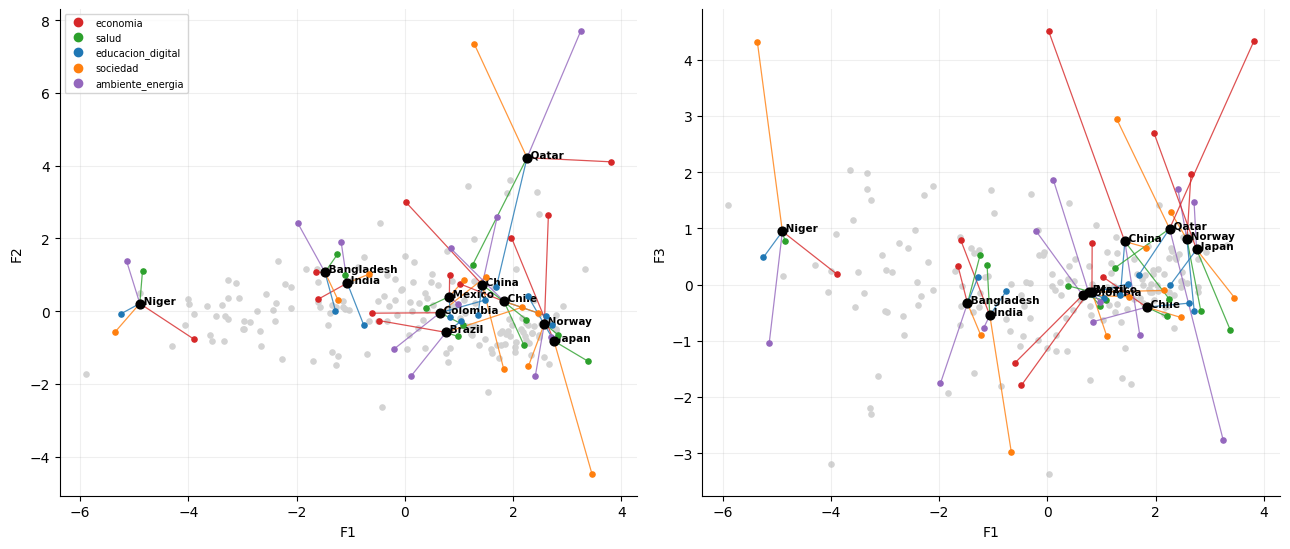

Paises mas desbalanceados entre temas (mayor dispersion de puntos parciales):
Lebanon                 5.5200
Sudan                   5.3800
Ukraine                 4.0600
Sao Tome and Principe   4.0200
Qatar                   3.9700
Saudi Arabia            3.6500
Oman                    3.6400
Syrian Arab Republic    3.5300

Lectura:
  Un punto parcial lejos del centro indica que ese tema ve al pais distinto del conjunto. Los paises mas desbalanceados son Lebanon, Sudan, Ukraine, Sao Tome and Principe; los mas coherentes entre temas, Philippines, Mexico, Spain.


In [21]:
sel = [p for p in ["Colombia", "Chile", "Brazil", "Mexico", "China", "India", "Norway", "Niger", "Nigeria", "Qatar", "Japan", "Bangladesh"] if p in nom]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.6))
for k, (a, b) in enumerate(((1, 2), (1, 3))):
    ax[k].scatter(F[:, a - 1], F[:, b - 1], c="lightgray", s=14)
    for p in sel:
        i = int(np.where(nom == p)[0][0]); c0 = F[i, [a - 1, b - 1]]; ax[k].scatter(*c0, c="k", s=40, zorder=5); ax[k].text(c0[0], c0[1], " " + p, fontsize=7.5, weight="bold")
        for g in grupos: pt = M["parcial"][g][i, [a - 1, b - 1]]; ax[k].plot([c0[0], pt[0]], [c0[1], pt[1]], c=COL_G[g], lw=.9, alpha=.8); ax[k].scatter(*pt, c=COL_G[g], s=14, zorder=4)
    ax[k].set_xlabel(f"F{a}"); ax[k].set_ylabel(f"F{b}"); ax[k].grid(alpha=.2)
ax[0].legend(handles=[plt.Line2D([0], [0], marker="o", ls="", c=c, label=g) for g, c in COL_G.items()], fontsize=7); plt.tight_layout(); plt.show()
# dispersion de los parciales por pais (distancia media de cada parcial a la coordenada global, en los 3 primeros ejes)
disp = np.sqrt(sum(((M["parcial"][g][:, :3] - F[:, :3]) ** 2).sum(axis=1) for g in grupos) / len(grupos)); disp = pd.Series(disp, index=nom)
print("Paises mas desbalanceados entre temas (mayor dispersion de puntos parciales):"); print(disp.sort_values(ascending=False).head(8).round(2).to_string())
print("\nLectura:")
print(f"  Un punto parcial lejos del centro indica que ese tema ve al pais distinto del conjunto. Los paises mas desbalanceados son {', '.join(disp.sort_values(ascending=False).index[:4])}; los mas coherentes entre temas, {', '.join(disp.sort_values().index[:3])}.")

## 9. Variables suplementarias: ingreso y región

Las categorías `ingreso` y `región` no intervinieron en el MFA. Su **baricentro** (media de las coordenadas de sus miembros) en el plano muestra dónde caen. El **v-test** mide si la media de una categoría en un eje difiere de la media global:
$$v=\frac{\bar F_{c,s}-\bar F_s}{\sqrt{\frac{n-n_c}{n-1}\cdot\frac{\lambda_s}{n_c}}}$$
($|v|>1{,}96$: diferencia significativa al 5 %). La incertidumbre de cada baricentro se visualiza con **elipses de bootstrap** (300 remuestras de los países).

Baricentros por nivel de ingreso:
                          n    v_F1    v_F2    v_F3      F1      F2      F3
Low income          19.0000 -8.1600 -0.7100 -0.4800 -3.7000 -0.1600 -0.0900
Lower middle income 43.0000 -5.9900  0.7300 -0.0400 -1.6600  0.1000 -0.0000
Upper middle income 54.0000  1.9700  0.1400 -1.9000  0.4600  0.0200 -0.1800
High income         55.0000  9.1000 -0.3500  2.2500  2.1200 -0.0400  0.2100

Por region (con v-test):
                                                        n    v_F1    v_F2    v_F3      F1      F2      F3
Sub-Saharan Africa                                42.0000 -9.1100 -0.0300  2.5100 -2.5600 -0.0000  0.2900
South Asia                                         6.0000 -0.7200  0.7900 -0.4500 -0.6000  0.3200 -0.1500
Middle East, North Africa, Afghanistan & Pakistan 22.0000  0.6700  7.7700 -5.2000  0.2800  1.5800 -0.8900
East Asia & Pacific                               25.0000  0.9400 -1.3400  2.9100  0.3700 -0.2500  0.4600
Latin America & Caribbean     

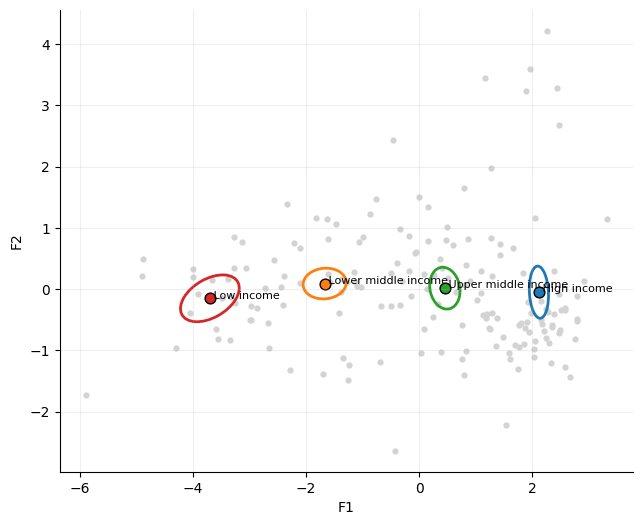

Lectura:
  El baricentro avanza de forma monotona en F1 con el ingreso: Low -3.70, Lower -1.66, Upper +0.46, High +2.12; todos con |v|>1.96 en F1 (True).
  Intervalos bootstrap del 95% de los baricentros en F1: solapamiento entre niveles consecutivos [np.False_, np.False_, np.False_]; en F2: [np.True_, np.True_, np.True_]. El ingreso discrimina el eje 1 y no el 2.
  Regiones con diferencia significativa en F2 o F3: Middle East, North Africa, Afghanistan & Pakistan, Sub-Saharan Africa, Europe & Central Asia, East Asia & Pacific; en F1 la region mas baja es Sub-Saharan Africa y la mas alta Europe & Central Asia.


In [22]:
def vtest(F, lam_, cats):
    n = len(F); out = {}
    for c in pd.unique(cats):
        m = cats == c; nc = m.sum()
        if nc < 3: continue
        out[c] = {"n": nc, **{f"v_F{s + 1}": (F[m, s].mean()) / np.sqrt((n - nc) / (n - 1) * lam_[s] / nc) for s in range(3)}, **{f"F{s + 1}": F[m, s].mean() for s in range(3)}}
    return pd.DataFrame(out).T
vt_ing = vtest(F, lam, ingreso).loc[ORD_ING]; vt_reg = vtest(F, lam, region)
print("Baricentros por nivel de ingreso:"); print(vt_ing.round(2).to_string()); print("\nPor region (con v-test):"); print(vt_reg.sort_values("F1").round(2).to_string())
fig, ax = plt.subplots(figsize=(7.4, 6)); ax.scatter(F[:, 0], F[:, 1], c="lightgray", s=12)
rg = np.random.default_rng(2); NB = 300; ic_F1 = {}
for cat in ORD_ING:
    m = ingreso == cat; pts = np.array([F[rg.choice(np.where(m)[0], m.sum()), :2].mean(axis=0) for _ in range(NB)]); mu_ = pts.mean(axis=0); cov = np.cov(pts.T); w_, v_ = np.linalg.eigh(cov)
    ic_F1[cat] = (np.percentile(pts[:, 0], 2.5), np.percentile(pts[:, 0], 97.5), np.percentile(pts[:, 1], 2.5), np.percentile(pts[:, 1], 97.5))
    ax.add_patch(Ellipse(mu_, 2 * 2.45 * np.sqrt(w_[1]), 2 * 2.45 * np.sqrt(w_[0]), angle=np.degrees(np.arctan2(v_[1, 1], v_[0, 1])), fill=False, ec=COL_ING[cat], lw=2)); ax.scatter(*mu_, c=COL_ING[cat], s=60, edgecolor="k"); ax.text(*mu_, " " + cat, fontsize=8)
ax.set_xlabel("F1"); ax.set_ylabel("F2"); ax.grid(alpha=.2); plt.show()
solapa_F1 = [ic_F1[a_][1] >= ic_F1[b_][0] for a_, b_ in zip(ORD_ING[:-1], ORD_ING[1:])]
solapa_F2 = [max(ic_F1[a_][2], ic_F1[b_][2]) <= min(ic_F1[a_][3], ic_F1[b_][3]) for a_, b_ in zip(ORD_ING[:-1], ORD_ING[1:])]
sig = vt_reg[(vt_reg.v_F2.abs() > 1.96) | (vt_reg.v_F3.abs() > 1.96)]
print("Lectura:")
print(f"  El baricentro avanza de forma monotona en F1 con el ingreso: {', '.join(f'{c.split()[0]} {vt_ing.loc[c, 'F1']:+.2f}' for c in ORD_ING)}; todos con |v|>1.96 en F1 ({(vt_ing.v_F1.abs() > 1.96).all()}).")
print(f"  Intervalos bootstrap del 95% de los baricentros en F1: solapamiento entre niveles consecutivos {solapa_F1}; en F2: {solapa_F2}. {'El ingreso discrimina el eje 1 y no el 2.' if not any(solapa_F1) and all(solapa_F2) else 'Ver detalle: la separacion no es limpia en todos los pares.'}")
print(f"  Regiones con diferencia significativa en F2 o F3: {', '.join(sig.index) if len(sig) else 'ninguna'}; en F1 la region mas baja es {vt_reg.F1.idxmin()} y la mas alta {vt_reg.F1.idxmax()}.")

## 10. Clusters de países (estilo HCPC)

Se agrupan los países en el espacio de los **primeros ejes retenidos** del MFA (esto elimina el ruido de los ejes bajos y equilibra los temas):

1. **Ward** sobre las coordenadas $F_1,F_2,F_3$ (minimiza el aumento de inercia intra-cluster).
2. **Consolidación k-means:** se parte de los centroides de Ward y se refina.
3. **Elección de $k$.** Indicadores: silhouette, Calinski–Harabasz, **estadístico gap** (referencia uniforme en la caja de los componentes principales) y estabilidad por *bootstrap* (**Jaccard** de Hennig: para cada cluster, la mayor similitud con algún cluster de la remuestra, promediada en 100 remuestras). **Regla fijada antes de ver los resultados:** entre $k\in\{3,\dots,6\}$ con Jaccard mínimo por cluster $\ge0{,}75$ (estable), se elige el de mayor silhouette; si ninguno cumple, el de mayor Jaccard mínimo.

In [23]:
from sklearn.metrics import calinski_harabasz_score
Zc = F[:, :N_AXES]
def ward_km(Z, k):
    L = linkage(Z, "ward"); lab = fcluster(L, k, "maxclust") - 1; cent = np.array([Z[lab == c].mean(axis=0) for c in range(k)])
    return KMeans(k, init=cent, n_init=1, max_iter=300).fit(Z).labels_
def W_k(Z, lab): return sum(((Z[lab == c] - Z[lab == c].mean(axis=0)) ** 2).sum() for c in np.unique(lab))
KS = range(2, 9); L_ward = linkage(Zc, "ward")
rg = np.random.default_rng(SEED); Uq, sq, Vq = np.linalg.svd(Zc - Zc.mean(axis=0), full_matrices=False); Zr = (Zc - Zc.mean(axis=0)) @ Vq.T
lo, hi = Zr.min(axis=0), Zr.max(axis=0); BG = 40
rows = []
labs = {k: ward_km(Zc, k) for k in KS}
for k in KS:
    lab = labs[k]; wk = np.log(W_k(Zc, lab)); ref = []
    for _ in range(BG): Zu = rg.uniform(lo, hi, Zr.shape); ref.append(np.log(W_k(Zu, ward_km(Zu, k))))
    gap = np.mean(ref) - wk; sk = np.std(ref) * np.sqrt(1 + 1 / BG)
    rows.append({"k": k, "silhouette": silhouette_score(Zc, lab), "Calinski_Harabasz": calinski_harabasz_score(Zc, lab), "gap": gap, "gap_sd": sk, "inercia_entre_%": 100 * (1 - W_k(Zc, lab) / W_k(Zc, np.zeros(len(Zc), int))), "tam_min": np.bincount(lab).min()})
sel_k = pd.DataFrame(rows).set_index("k")
sel_k["gap_regla_Tibshirani"] = [sel_k.gap[k] >= sel_k.gap[k + 1] - sel_k.gap_sd[k + 1] if k + 1 in sel_k.index else np.nan for k in sel_k.index]
print(sel_k.round(3).to_string())

   silhouette  Calinski_Harabasz    gap  gap_sd  inercia_entre_%  tam_min gap_regla_Tibshirani
k                                                                                             
2      0.4670           189.9280 1.0060  0.0480          52.9150       60                 True
3      0.3590           148.0150 1.0300  0.0430          63.7950       53                 True
4      0.3220           128.1160 1.0040  0.0450          69.7110       23                 True
5      0.3360           126.7940 1.0380  0.0530          75.3410        7                 True
6      0.3450           115.5190 1.0090  0.0500          77.7810        7                 True
7      0.3510           114.3200 1.0130  0.0570          80.7040        5                 True
8      0.3390           113.7310 1.0390  0.0470          83.0050        4                  NaN


   silhouette    gap  jaccard_medio  jaccard_minimo
k                                                  
2      0.4670 1.0060         0.9690          0.9600
3      0.3590 1.0300         0.7510          0.6270
4      0.3220 1.0040         0.6320          0.4660
5      0.3360 1.0380         0.7280          0.5640
6      0.3450 1.0090         0.6460          0.3620
7      0.3510 1.0130         0.6560          0.4150
8      0.3390 1.0390         0.6940          0.5300

Candidatos estables (Jaccard minimo >= 0.75) entre k=3..6: []  ->  k elegido = 3


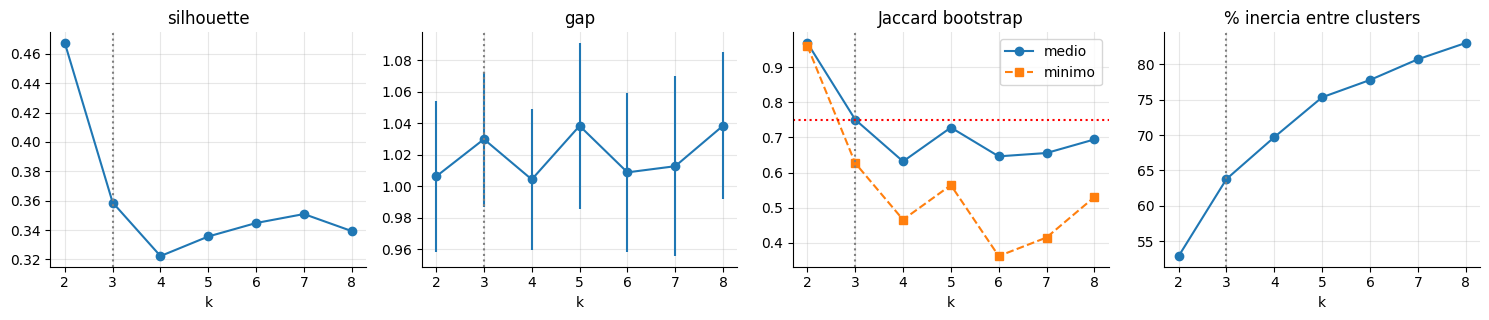

In [24]:
def jaccard_boot(Z, k, B=100, seed=0):
    rg = np.random.default_rng(seed); base = ward_km(Z, k); n = len(Z); J = np.zeros((B, k))
    for b in range(B):
        idx = np.unique(rg.integers(0, n, n)); lb = ward_km(Z[idx], k)
        for c in range(k):
            A = set(np.where(base == c)[0]) & set(idx)
            J[b, c] = max(len(A & set(idx[lb == d])) / len(A | set(idx[lb == d])) for d in range(k)) if A else np.nan
    return np.nanmean(J, axis=0)
jac = {k: jaccard_boot(Zc, k, seed=k) for k in range(2, 9)}
sel_k["jaccard_medio"] = [jac[k].mean() for k in sel_k.index]; sel_k["jaccard_minimo"] = [jac[k].min() for k in sel_k.index]
cand = sel_k.loc[3:6]; estables = cand[cand.jaccard_minimo >= 0.75]
K_CL = int(estables.silhouette.idxmax()) if len(estables) else int(cand.jaccard_minimo.idxmax())
print(sel_k[["silhouette", "gap", "jaccard_medio", "jaccard_minimo"]].round(3).to_string())
print(f"\nCandidatos estables (Jaccard minimo >= 0.75) entre k=3..6: {list(estables.index)}  ->  k elegido = {K_CL}")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.3))
ax[0].plot(sel_k.index, sel_k.silhouette, "o-"); ax[0].set_title("silhouette"); ax[1].plot(sel_k.index, sel_k.gap, "o-"); ax[1].errorbar(sel_k.index, sel_k.gap, sel_k.gap_sd, fmt="none"); ax[1].set_title("gap")
ax[2].plot(sel_k.index, sel_k.jaccard_medio, "o-", label="medio"); ax[2].plot(sel_k.index, sel_k.jaccard_minimo, "s--", label="minimo"); ax[2].axhline(.75, c="r", ls=":"); ax[2].legend(); ax[2].set_title("Jaccard bootstrap")
ax[3].plot(sel_k.index, sel_k["inercia_entre_%"], "o-"); ax[3].set_title("% inercia entre clusters")
for a_ in ax: a_.set_xlabel("k"); a_.axvline(K_CL, c="gray", ls=":")
plt.tight_layout(); plt.show()

In [25]:
print("Lectura:")
print(f"  k=2 es la unica particion claramente estable (Jaccard minimo {sel_k.loc[2, 'jaccard_minimo']:.2f}, silhouette {sel_k.loc[2, 'silhouette']:.2f}); para k>=3 el Jaccard minimo cae a {sel_k.loc[3:6, 'jaccard_minimo'].min():.2f}-{sel_k.loc[3:6, 'jaccard_minimo'].max():.2f}: ninguno cumple la regla de 0.75.")
print(f"  El gap casi no varia con k ({sel_k.gap.min():.2f} a {sel_k.gap.max():.2f}, con desvio ~{sel_k.gap_sd.mean():.2f}) y cumple la regla de Tibshirani ya en k=2: no hay evidencia de grupos separados por vacios frente a una nube uniforme; los paises forman un CONTINUO de desarrollo que se puede cortar.")
print(f"  Por la regla fijada de antemano se usa k={K_CL} (el de mayor Jaccard minimo = {sel_k.loc[K_CL, 'jaccard_minimo']:.2f}, 'patron valido pero con fronteras difusas' en la escala de Hennig, 0.6-0.75), y se informa tambien k=2. Las fronteras entre clusters se cuantifican abajo con la probabilidad de co-asignacion.")

Lectura:
  k=2 es la unica particion claramente estable (Jaccard minimo 0.96, silhouette 0.47); para k>=3 el Jaccard minimo cae a 0.36-0.63: ninguno cumple la regla de 0.75.
  El gap casi no varia con k (1.00 a 1.04, con desvio ~0.05) y cumple la regla de Tibshirani ya en k=2: no hay evidencia de grupos separados por vacios frente a una nube uniforme; los paises forman un CONTINUO de desarrollo que se puede cortar.
  Por la regla fijada de antemano se usa k=3 (el de mayor Jaccard minimo = 0.63, 'patron valido pero con fronteras difusas' en la escala de Hennig, 0.6-0.75), y se informa tambien k=2. Las fronteras entre clusters se cuantifican abajo con la probabilidad de co-asignacion.


## 11. Descripción de los clusters y planos

Los clusters se ordenan por su media en $F_1$ (de menor a mayor desarrollo) y se describen con: tamaño y composición por ingreso, **v-test de cada variable** (diferencia de la media del cluster frente a la global, en desviaciones), contribución por grupo y países **paragón** (más cercanos al centro del cluster). La **incertidumbre de pertenencia** se mide con la probabilidad de co-asignación: en 200 remuestras *bootstrap*, la fracción de veces que cada país queda en el mismo cluster que su cluster base (alineando por Jaccard).

In [26]:
lab0 = labs[K_CL]; orden_c = np.argsort([F[lab0 == c, 0].mean() for c in range(K_CL)]); remap = {old: new for new, old in enumerate(orden_c)}; lab = np.array([remap[x] for x in lab0])
NC = [f"C{c + 1}" for c in range(K_CL)]
# probabilidad de pertenencia por bootstrap (alineacion por Jaccard con el cluster base)
rg = np.random.default_rng(11); BB = 200; hit = np.zeros(len(Zc)); veces = np.zeros(len(Zc)); asign = np.zeros((len(Zc), K_CL))
for b in range(BB):
    idx = np.unique(rg.integers(0, len(Zc), len(Zc))); lb = ward_km(Zc[idx], K_CL)
    mapa = {d: int(np.argmax([len(set(np.where(lab == c)[0]) & set(idx[lb == d])) / len(set(np.where(lab == c)[0]) | set(idx[lb == d])) for c in range(K_CL)])) for d in range(K_CL)}
    for j, i in enumerate(idx): asign[i, mapa[lb[j]]] += 1
    veces[idx] += 1
prob = asign / np.maximum(veces[:, None], 1); p_own = prob[np.arange(len(Zc)), lab]
resumen = pd.DataFrame({"n": np.bincount(lab), "F1_medio": [F[lab == c, 0].mean() for c in range(K_CL)], "F2_medio": [F[lab == c, 1].mean() for c in range(K_CL)], "F3_medio": [F[lab == c, 2].mean() for c in range(K_CL)],
                        "P(pertenencia)_media": [p_own[lab == c].mean() for c in range(K_CL)], "paises_dudosos(<0.7)": [(p_own[lab == c] < 0.7).sum() for c in range(K_CL)]}, index=NC)
comp = pd.crosstab(lab, ingreso).reindex(columns=ORD_ING, fill_value=0); comp.index = NC
print(resumen.round(2).to_string()); print("\nComposicion por nivel de ingreso:"); print(comp.to_string())
vt = pd.DataFrame({NC[c]: [(D[v].values[lab == c].mean() - D[v].mean()) / np.sqrt((len(D) - (lab == c).sum()) / (len(D) - 1) * D[v].var(ddof=0) / (lab == c).sum()) for v in D.columns] for c in range(K_CL)}, index=D.columns)
for c in NC: print(f"\n{c}: mas altas: " + ", ".join(f"{v} ({vt.loc[v, c]:+.1f})" for v in vt[c].sort_values(ascending=False).index[:4]) + " | mas bajas: " + ", ".join(f"{v} ({vt.loc[v, c]:+.1f})" for v in vt[c].sort_values().index[:4]))

     n  F1_medio  F2_medio  F3_medio  P(pertenencia)_media  paises_dudosos(<0.7)
C1  55   -2.6000   -0.0800    0.0800                0.8200                    18
C2  53    0.4600    0.8500   -0.1100                0.7600                    16
C3  63    1.8800   -0.6400    0.0200                0.9700                     2

Composicion por nivel de ingreso:
col_0  Low income  Lower middle income  Upper middle income  High income
C1             19                   32                    4            0
C2              0                   11                   33            9
C3              0                    0                   17           46

C1: mas altas: fecundidad (+10.4), mortalidad_neonatal (+10.1), mortalidad_infantil (+9.6), dependencia (+9.6) | mas bajas: usuarios_internet (-10.8), electricidad_pc (-10.5), pib_pc_ppa (-10.4), matricula_secundaria (-9.6)

C2: mas altas: industria_pib (+4.4), pm25 (+3.9), celulares_100hab (+3.4), usuarios_internet (+3.4) | mas bajas: dependenci

C1 paragones: Kenya, Togo, Rwanda, Lesotho, Gambia, The
C2 paragones: Mongolia, Azerbaijan, South Africa, Kazakhstan, Mexico
C3 paragones: Hungary, Belarus, Lithuania, Slovak Republic, France

Paises de frontera (menor probabilidad de pertenencia a su cluster):
             pais cluster  P_pertenencia cluster_mas_frecuente_en_bootstrap  P_en_ese
Brunei Darussalam      C2         0.1900                                 C3    0.8100
           Israel      C2         0.1900                                 C3    0.8100
            Tonga      C1         0.2100                                 C2    0.7800
            China      C2         0.3100                                 C3    0.6900
           Panama      C2         0.3400                                 C3    0.6600
         Malaysia      C2         0.3600                                 C3    0.6400
        Guatemala      C1         0.3600                                 C2    0.6400
         Maldives      C2         0.3700          

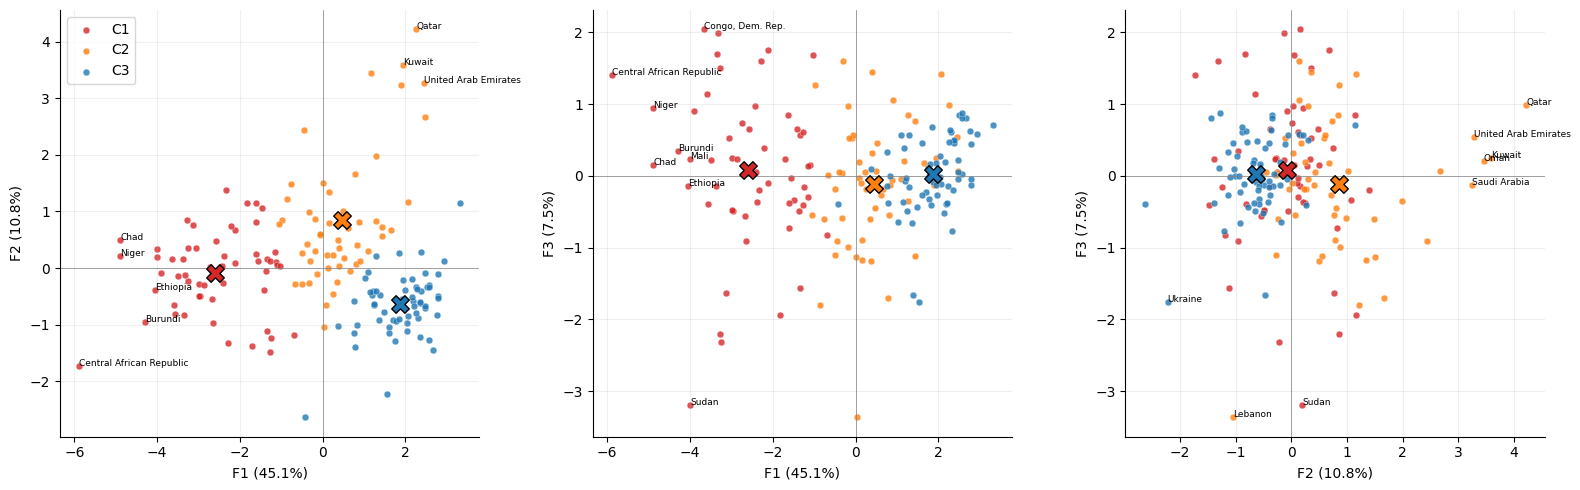

In [27]:
paragon = {c: list(pd.Series(nom)[lab == i].iloc[np.argsort(((Zc[lab == i] - Zc[lab == i].mean(axis=0)) ** 2).sum(axis=1))[:5]]) for i, c in enumerate(NC)}
dudosos = pd.DataFrame({"pais": nom, "cluster": [NC[x] for x in lab], "P_pertenencia": p_own, "cluster_mas_frecuente_en_bootstrap": [NC[int(np.argmax(prob[i]))] for i in range(len(nom))], "P_en_ese": prob.max(axis=1)}).sort_values("P_pertenencia").head(10)
for c in NC: print(f"{c} paragones: {', '.join(paragon[c])}")
print("\nPaises de frontera (menor probabilidad de pertenencia a su cluster):"); print(dudosos.round(2).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(16, 5)); COL_C = ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b"][:K_CL]
for k_, (a, b) in enumerate(((1, 2), (1, 3), (2, 3))):
    for c in range(K_CL):
        m = lab == c; ax[k_].scatter(F[m, a - 1], F[m, b - 1], c=COL_C[c], s=24, alpha=.8, label=NC[c], edgecolor="white", lw=.3)
        pts = F[m][:, [a - 1, b - 1]]; ctr_ = pts.mean(axis=0); ax[k_].scatter(*ctr_, c=COL_C[c], s=160, marker="X", edgecolor="k", zorder=5)
    for i in np.argsort(-(F[:, a - 1] ** 2 + F[:, b - 1] ** 2))[:8]: ax[k_].text(F[i, a - 1], F[i, b - 1], nom[i], fontsize=6.5)
    ax[k_].set_xlabel(f"F{a} ({100 * lam[a - 1] / tot:.1f}%)"); ax[k_].set_ylabel(f"F{b} ({100 * lam[b - 1] / tot:.1f}%)"); ax[k_].axhline(0, c="gray", lw=.5); ax[k_].axvline(0, c="gray", lw=.5); ax[k_].grid(alpha=.2)
ax[0].legend(); plt.tight_layout(); plt.show()

In [28]:
ari_ing = adjusted_rand_score(ingreso, lab); ari_reg = adjusted_rand_score(region, lab); ari_ing_perm = np.mean([adjusted_rand_score(np.random.default_rng(i).permutation(ingreso), lab) for i in range(200)])
print("Lectura:")
print(f"  {NC[0]} (n={resumen.loc[NC[0], 'n']}) es el cluster de menor desarrollo: {comp.loc[NC[0]].idxmax()} domina ({comp.loc[NC[0]].max()} de {comp.loc[NC[0]].sum()}); {NC[-1]} (n={resumen.loc[NC[-1], 'n']}) el de mayor: {comp.loc[NC[-1]].idxmax()} ({comp.loc[NC[-1]].max()} de {comp.loc[NC[-1]].sum()}).")
extremo = vt.abs().max(axis=0)
print(f"  Probabilidad media de pertenencia: " + ", ".join(f"{c} {resumen.loc[c, 'P(pertenencia)_media']:.2f}" for c in NC) + f"; {int((p_own < 0.7).sum())} de {len(p_own)} paises ({(p_own < 0.7).mean():.0%}) tienen menos de 70% de probabilidad: las fronteras son borrosas, como indicaba el Jaccard.")
print(f"  Validacion externa (variables NO usadas): ARI con nivel de ingreso = {ari_ing:.2f} (azar ~ {ari_ing_perm:.2f}); con region = {ari_reg:.2f}. {'Se asocian mas con el ingreso que con la region' if ari_ing > ari_reg else 'Se asocian mas con la region que con el ingreso'}, pero la correspondencia es parcial: los clusters son perfiles multivariados, no una copia de las categorias del Banco Mundial.")

Lectura:
  C1 (n=55) es el cluster de menor desarrollo: Lower middle income domina (32 de 55); C3 (n=63) el de mayor: High income (46 de 63).
  Probabilidad media de pertenencia: C1 0.82, C2 0.76, C3 0.97; 36 de 171 paises (21%) tienen menos de 70% de probabilidad: las fronteras son borrosas, como indicaba el Jaccard.
  Validacion externa (variables NO usadas): ARI con nivel de ingreso = 0.37 (azar ~ 0.00); con region = 0.30. Se asocian mas con el ingreso que con la region, pero la correspondencia es parcial: los clusters son perfiles multivariados, no una copia de las categorias del Banco Mundial.


## 12. Robustez: ¿cuánto dependen los resultados de las decisiones del analista?

Cada decisión se cambia **una a la vez** y se mide cuánto se parecen los resultados al análisis base:

- **Configuración de los países (coordenadas):** coeficiente $RV$ entre las configuraciones $F_{1..3}$ base y alterna, sobre los países comunes ($RV=1$ si son idénticas salvo rotación/escala), y $|\text{corr}|$ del eje 1.
- **Clusters:** índice de Rand ajustado (ARI) entre las particiones base y alterna, sobre los países comunes, con $k=2$ y con $k=3$ (se recalculan los clusters en cada variante).

Variantes: sin transformaciones logarítmicas; solo casos completos (sin imputar); otro rango de imputación (1, 3, 5); umbral de cobertura 70 % y 95 %; **ACP** en lugar de MFA; quitar un grupo a la vez; usar 2, 4 o 5 ejes para los clusters.

In [29]:
def rv_conf(X, Y):
    X = X - X.mean(axis=0); Y = Y - Y.mean(axis=0); A = X.T @ Y; return np.linalg.norm(A, "fro") ** 2 / (np.linalg.norm(X.T @ X, "fro") * np.linalg.norm(Y.T @ Y, "fro"))
def pipeline(transf=True, umbral=0.85, r=None, completo=False, gr=None, ejes=N_AXES, motor="mfa"):
    gr = gr or grupos; Tt = transformar(W, transf); cobp = Tt.notna().mean(axis=1); Tt = Tt[cobp >= (1.0 if completo else umbral)][sum(gr.values(), [])]
    Xi, _ = imputar_acp(Tt.values, r or R_IMP) if Tt.isna().values.any() else (Tt.values, None); Dv = pd.DataFrame(Xi, index=Tt.index, columns=Tt.columns)
    Mv = mfa(Dv, gr) if motor == "mfa" else acp(Dv); Fv = Mv["F"][:, :max(ejes, 3)]
    return Dv, Mv, Fv
def comparar(nombre, **kw):
    Dv, Mv, Fv = pipeline(**kw); comunes = D.index.intersection(Dv.index); ib = [D.index.get_loc(i) for i in comunes]; iv = [Dv.index.get_loc(i) for i in comunes]; ej = kw.get("ejes", N_AXES)
    fila = {"variante": nombre, "n_paises": len(Dv), "comunes": len(comunes), "RV_configuracion_3ejes": rv_conf(F[ib, :3], Fv[iv, :3]), "|corr|_eje1": abs(np.corrcoef(F[ib, 0], Fv[iv, 0])[0, 1])}
    for k in (2, K_CL):
        lv = ward_km(Fv[:, :ej], k); lb = ward_km(F[:, :N_AXES], k)[ib]; fila[f"ARI_k={k}"] = adjusted_rand_score(lb, lv[iv])
    return fila
VAR = [("base (referencia)", {}), ("sin transformaciones", {"transf": False}), ("solo casos completos", {"completo": True}), ("imputacion r=1", {"r": 1}), ("imputacion r=3", {"r": 3}), ("imputacion r=5", {"r": 5}),
       ("cobertura >= 70%", {"umbral": 0.70}), ("cobertura >= 95%", {"umbral": 0.95}), ("ACP en vez de MFA", {"motor": "acp"})]
for g in grupos: VAR.append((f"sin el grupo {g}", {"gr": {k: v for k, v in grupos.items() if k != g}}))
for e in (2, 4, 5): VAR.append((f"clusters con {e} ejes", {"ejes": e}))
rob = pd.DataFrame([comparar(n, **kw) for n, kw in VAR]).set_index("variante"); rob.round(3)

,n_paises,comunes,RV_configuracion_3ejes,|corr|_eje1,ARI_k=2,ARI_k=3
variante,,,,,,
base (referencia),171,171,1.0000,1.0000,1.0000,1.0000
sin transformaciones,171,171,0.9790,0.9960,0.9530,0.6740
solo casos completos,107,107,0.9980,1.0000,0.9610,0.9150
imputacion r=1,171,171,1.0000,1.0000,1.0000,0.5140
imputacion r=3,171,171,1.0000,1.0000,1.0000,0.5140
imputacion r=5,171,171,0.9990,1.0000,1.0000,0.9820
cobertura >= 70%,196,171,0.9990,1.0000,1.0000,0.5520
cobertura >= 95%,136,136,0.9990,1.0000,1.0000,0.7360
ACP en vez de MFA,171,171,0.9970,0.9990,0.9760,0.5060


In [30]:
r_ = rob.drop("base (referencia)")
print("Lectura:")
print(f"  Las decisiones de preparacion de datos (transformacion, imputacion, umbral, casos completos) conservan la configuracion: RV entre {r_.loc[[i for i in r_.index if i.startswith(('sin transf', 'solo casos', 'imputacion', 'cobertura'))], 'RV_configuracion_3ejes'].min():.2f} y {r_.loc[[i for i in r_.index if i.startswith(('sin transf', 'solo casos', 'imputacion', 'cobertura'))], 'RV_configuracion_3ejes'].max():.2f}; el eje 1 es casi identico (|corr| >= {r_['|corr|_eje1'].min():.3f} en todas las variantes).")
print(f"  Clusters con k=2: ARI entre {r_['ARI_k=2'].min():.2f} y {r_['ARI_k=2'].max():.2f}; con k={K_CL}: entre {r_[f'ARI_k={K_CL}'].min():.2f} y {r_[f'ARI_k={K_CL}'].max():.2f} (mediana {r_[f'ARI_k={K_CL}'].median():.2f}). La particion en 2 es robusta; la de {K_CL} cambia mas, en linea con su Jaccard.")
peor = r_[f"ARI_k={K_CL}"].idxmin(); print(f"  La variante que mas altera la particion de {K_CL} clusters es '{peor}' (ARI {r_.loc[peor, f'ARI_k={K_CL}']:.2f}).")
dg = r_.loc[[i for i in r_.index if i.startswith('sin el grupo')]]; print(f"  Quitar un grupo: el que mas cambia la configuracion es '{dg['RV_configuracion_3ejes'].idxmin().replace('sin el grupo ', '')}' (RV {dg['RV_configuracion_3ejes'].min():.2f}); el que menos, '{dg['RV_configuracion_3ejes'].idxmax().replace('sin el grupo ', '')}' (RV {dg['RV_configuracion_3ejes'].max():.2f}): cada tema aporta informacion distinta, pero el eje 1 de desarrollo lo comparten todos (|corr| >= {dg['|corr|_eje1'].min():.2f}).")
print(f"  ACP en vez de MFA: RV {r_.loc['ACP en vez de MFA', 'RV_configuracion_3ejes']:.2f}, ARI k={K_CL} {r_.loc['ACP en vez de MFA', f'ARI_k={K_CL}']:.2f}.")

Lectura:
  Las decisiones de preparacion de datos (transformacion, imputacion, umbral, casos completos) conservan la configuracion: RV entre 0.98 y 1.00; el eje 1 es casi identico (|corr| >= 0.994 en todas las variantes).
  Clusters con k=2: ARI entre 0.89 y 1.00; con k=3: entre 0.47 y 0.98 (mediana 0.72). La particion en 2 es robusta; la de 3 cambia mas, en linea con su Jaccard.
  La variante que mas altera la particion de 3 clusters es 'sin el grupo sociedad' (ARI 0.47).
  Quitar un grupo: el que mas cambia la configuracion es 'sociedad' (RV 0.98); el que menos, 'educacion_digital' (RV 0.99): cada tema aporta informacion distinta, pero el eje 1 de desarrollo lo comparten todos (|corr| >= 0.99).
  ACP en vez de MFA: RV 1.00, ARI k=3 0.51.


### 12.1 Qué pesa el ACP frente al MFA en estos datos

Con grupos de tamaño parecido (5-6 variables) la diferencia es moderada, pero el ACP deja que los grupos con más estructura interna pesen más en el eje 1. Se compara la **contribución de cada grupo** a los 3 primeros ejes en el ACP normado y en el MFA.

In [31]:
Pa = acp(D); gi = {g: [list(D.columns).index(c) for c in vs] for g, vs in grupos.items()}
cg_acp = pd.DataFrame({g: (Pa["Vt"].T[:, :3][gi[g]] ** 2).sum(axis=0) for g in grupos}, index=["F1", "F2", "F3"]).T
cmp_cg = pd.concat({"ACP": cg_acp, "MFA": M["contrib_g"].iloc[:, :3]}, axis=1)
print(cmp_cg.round(3).to_string())
sd_acp = cg_acp.std(); sd_mfa = M["contrib_g"].iloc[:, :3].std(); print("\nDesvio de las contribuciones entre grupos (0 = reparto perfecto):"); print(pd.DataFrame({"ACP": sd_acp, "MFA": sd_mfa.values}).round(3).to_string())

                     ACP                  MFA              
                      F1     F2     F3     F1     F2     F3
economia          0.1520 0.2090 0.3660 0.1860 0.2070 0.3860
salud             0.2610 0.1250 0.0330 0.2050 0.0720 0.0190
educacion_digital 0.2610 0.0550 0.0160 0.2070 0.0310 0.0100
sociedad          0.1500 0.2940 0.3260 0.2010 0.3680 0.3890
ambiente_energia  0.1760 0.3180 0.2590 0.2000 0.3210 0.1950

Desvio de las contribuciones entre grupos (0 = reparto perfecto):
      ACP    MFA
F1 0.0570 0.0080
F2 0.1110 0.1480
F3 0.1650 0.1870


In [32]:
print("Lectura:")
print(f"  Eje 1: el reparto entre grupos es {'mas parejo' if sd_mfa.iloc[0] < sd_acp.iloc[0] else 'menos parejo'} con MFA (desvio {sd_mfa.iloc[0]:.3f} frente a {sd_acp.iloc[0]:.3f} con ACP).")
print(f"  Ejes 2 y 3: el reparto NO es mas parejo con MFA (desvio {sd_mfa.iloc[1]:.3f} y {sd_mfa.iloc[2]:.3f} frente a {sd_acp.iloc[1]:.3f} y {sd_acp.iloc[2]:.3f}): el balanceo iguala el peso del PRIMER eje de cada grupo, y desde el eje 2 cada eje lo definen los temas con estructura propia (ahi {M['contrib_g']['F2'].idxmax()} aporta {M['contrib_g']['F2'].max():.0%} del eje 2 en el MFA frente a {cg_acp['F2'].idxmax()} {cg_acp['F2'].max():.0%} en el ACP). Es una limitacion y no un defecto: el MFA protege del dominio de un grupo en el eje comun, no impone igualdad en los demas.")

Lectura:
  Eje 1: el reparto entre grupos es mas parejo con MFA (desvio 0.008 frente a 0.057 con ACP).
  Ejes 2 y 3: el reparto NO es mas parejo con MFA (desvio 0.148 y 0.187 frente a 0.111 y 0.165): el balanceo iguala el peso del PRIMER eje de cada grupo, y desde el eje 2 cada eje lo definen los temas con estructura propia (ahi sociedad aporta 37% del eje 2 en el MFA frente a ambiente_energia 32% en el ACP). Es una limitacion y no un defecto: el MFA protege del dominio de un grupo en el eje comun, no impone igualdad en los demas.


### 12.2 Estabilidad de los autovalores y de cada eje; influencia de países individuales

Con 300 remuestras *bootstrap* de países: intervalos del 95 % de los autovalores y el **congruence de Tucker** de las cargas de cada eje con el eje base (tras alinear signos; 1 = idénticas). Además, el efecto de **quitar un país a la vez** (171 MFA): ángulo máximo entre los subespacios de los 3 primeros ejes.

In [33]:
rg = np.random.default_rng(9); BO = 300; eigs = np.zeros((BO, 6)); tuck = np.zeros((BO, 4)); V0 = M["Vt"].T
for b in range(BO):
    idx = rg.integers(0, len(D), len(D)); Mb = mfa(D.iloc[idx], grupos); eigs[b] = Mb["eig"][:6]; Vb = Mb["Vt"].T
    for s_ in range(4): c_ = V0[:, s_] @ Vb[:, s_]; tuck[b, s_] = abs(c_)
ci = pd.DataFrame({"autovalor": lam[:6], "P2.5": np.percentile(eigs, 2.5, axis=0), "P97.5": np.percentile(eigs, 97.5, axis=0)}, index=[f"F{i + 1}" for i in range(6)])
tk = pd.DataFrame({"|congruence| mediano": np.median(tuck, axis=0), "P5": np.percentile(tuck, 5, axis=0)}, index=[f"F{i + 1}" for i in range(4)])
print(ci.round(3).to_string()); print(); print(tk.round(3).to_string())
loo = []
for i in range(len(D)):
    Vi = mfa(D.drop(D.index[i]), grupos)["Vt"].T; loo.append(np.degrees(np.arccos(np.clip(np.linalg.svd(V0[:, :3].T @ Vi[:, :3], compute_uv=False).min(), -1, 1))))
loo = pd.Series(loo, index=nom).sort_values(ascending=False); print("\nPaises cuya salida mas mueve el subespacio de 3 ejes (angulo maximo, grados):"); print(loo.head(6).round(2).to_string()); print(f"mediana de todos: {loo.median():.2f}")

    autovalor   P2.5  P97.5
F1     4.3670 4.2620 4.4590
F2     1.0420 0.7970 1.4060
F3     0.7300 0.6160 0.8700
F4     0.4830 0.4390 0.6070
F5     0.4230 0.3680 0.5070
F6     0.3750 0.3200 0.4330

    |congruence| mediano     P5
F1                0.9970 0.9930
F2                0.9740 0.7600
F3                0.9310 0.7070
F4                0.7800 0.2320



Paises cuya salida mas mueve el subespacio de 3 ejes (angulo maximo, grados):
Lebanon                    9.4000
Sudan                      7.9600
Iran, Islamic Rep.         4.3400
Qatar                      4.2100
Central African Republic   4.1100
Afghanistan                4.0600
mediana de todos: 0.87


In [34]:
print("Lectura:")
print(f"  El autovalor del eje 1 ({lam[0]:.2f}) tiene un intervalo del 95% de [{ci.loc['F1', 'P2.5']:.2f}, {ci.loc['F1', 'P97.5']:.2f}]; el del eje 2, [{ci.loc['F2', 'P2.5']:.2f}, {ci.loc['F2', 'P97.5']:.2f}] y el del eje 3, [{ci.loc['F3', 'P2.5']:.2f}, {ci.loc['F3', 'P97.5']:.2f}] (se traslapan: los ejes 2 y 3 pueden intercambiarse).")
print(f"  Congruence mediano con el eje base: F1 {tk.loc['F1', '|congruence| mediano']:.3f}, F2 {tk.loc['F2', '|congruence| mediano']:.3f}, F3 {tk.loc['F3', '|congruence| mediano']:.3f}, F4 {tk.loc['F4', '|congruence| mediano']:.3f}: el eje 1 es muy estable; los ejes 2 y 3 son interpretables pero menos precisos; el 4 no es confiable.")
print(f"  Ningun pais individual rompe el analisis: el angulo maximo al quitarlo es {loo.max():.1f} grados ({loo.index[0]}); la mediana es {loo.median():.2f}.")

Lectura:
  El autovalor del eje 1 (4.37) tiene un intervalo del 95% de [4.26, 4.46]; el del eje 2, [0.80, 1.41] y el del eje 3, [0.62, 0.87] (se traslapan: los ejes 2 y 3 pueden intercambiarse).
  Congruence mediano con el eje base: F1 0.997, F2 0.974, F3 0.931, F4 0.780: el eje 1 es muy estable; los ejes 2 y 3 son interpretables pero menos precisos; el 4 no es confiable.
  Ningun pais individual rompe el analisis: el angulo maximo al quitarlo es 9.4 grados (Lebanon); la mediana es 0.87.


## 13. Pruebas automáticas

In [35]:
# 13.1 motor: identidades exactas
assert (np.diff(M["eig"]) <= 1e-12).all() and all(abs(M["lam1"][g] * M["peso_g"][g] - 1) < 1e-10 for g in grupos)
assert np.abs(sum(M["parcial"].values()) / len(grupos) - M["F"]).max() < 1e-10 and np.abs((M["F"].T @ M["F"]) / len(D) - np.diag(M["eig"])).max() < 1e-10
assert abs(M["eig"].sum() - sum(M["acp_g"][g]["eig"].sum() / M["lam1"][g] for g in grupos)) < 1e-9 and np.allclose(M["contrib_g"].sum(axis=0), 1) and (M["eig"] <= len(grupos) + 1e-9).all()
# 13.2 con un solo grupo el MFA es el ACP normado
assert np.abs(M1["eig"] * M1["lam1"]["todo"] - ev_corr).max() < 1e-9
# 13.3 mundo sintetico: el MFA reduce el dominio del grupo redundante y recupera los clusters
assert cg_pca.loc["A", "F1"] > 0.6 and Ms["contrib_g"].loc["A", "F1"] < 0.4 and ari_s["MFA"] > 0.9
# 13.4 datos: dimension, grupos, imputacion que respeta lo observado
assert D.shape == (171, 26) and len(grupos) == 5 and sum(len(v) for v in grupos.values()) == 26 and np.allclose(D.values[~faltaba], Tk.values[~faltaba]) and not np.isnan(D.values).any()
assert faltaba.mean() < 0.05 and R_IMP in (1, 2, 3, 4) and cvimp.loc[R_IMP, "RMSE_estandarizado"] < 0.9
# 13.5 los grupos comparten estructura: todos los RV son significativos
assert np.nanmax(pval.values) < 0.01 and RV.values[np.triu_indices(5, 1)].min() > 0.3
# 13.6 el eje 1 es el desarrollo: correlaciones y ordenamiento de ingreso (variable no usada)
assert 4.0 < M["eig"][0] <= 5 and M["eig"][0] / M["eig"].sum() > 0.40
assert M["corr"].loc["pib_pc_ppa", "F1"] > 0.85 and M["corr"].loc["esperanza_vida", "F1"] > 0.7 and M["corr"].loc["mortalidad_infantil", "F1"] < -0.85 and rho_ing > 0.85
assert (np.diff(vt_ing["F1"].values.astype(float)) > 0).all() and (vt_ing["v_F1"].abs() > 1.96).all()
# 13.7 numero de ejes y estabilidad
assert N_AXES >= 2 and estab.loc[1, "coseno_min_medio"] > 0.95 and estab.loc[N_AXES, "coseno_min_medio"] >= 0.9 and estab.loc[N_AXES + 1, "coseno_min_medio"] < estab.loc[N_AXES, "coseno_min_medio"]
# 13.8 clusters: k=2 muy estable; k elegido por la regla; orden por F1; validacion externa
assert sel_k.loc[2, "jaccard_minimo"] > 0.9 and ((K_CL in estables.index) if len(estables) else (sel_k.loc[K_CL, "jaccard_minimo"] == sel_k.loc[3:6, "jaccard_minimo"].max()))
assert all(resumen["F1_medio"].values[i] < resumen["F1_medio"].values[i + 1] for i in range(K_CL - 1)) and resumen["n"].sum() == len(D) and ari_ing > 5 * max(ari_ing_perm, 0.01) and ari_ing > 0.25
assert prob.sum(axis=1).round(6).max() <= 1 + 1e-9 and (p_own >= 0).all()
# 13.9 robustez: preparacion de datos no cambia la configuracion; el eje 1 es identico en todas las variantes; k=2 robusto
prep = [i for i in rob.index if i.startswith(("sin transf", "solo casos", "imputacion", "cobertura"))]
assert (rob.loc[prep, "RV_configuracion_3ejes"] > 0.95).all() and (rob["|corr|_eje1"] > 0.98).all() and (rob["ARI_k=2"] > 0.8).all()
assert rob.loc["base (referencia)", "RV_configuracion_3ejes"] > 0.999999 and abs(rob.loc["base (referencia)", f"ARI_k={K_CL}"] - 1) < 1e-9
# 13.10 bootstrap: el autovalor base cae en su intervalo (aprox.) y el eje 1 es muy estable; ningun pais rompe el analisis
assert (ci["P2.5"] < ci["autovalor"] * 1.1).all() and (ci["P97.5"] > ci["autovalor"] * 0.9).all() and tk.loc["F1", "|congruence| mediano"] > 0.99 and tk.loc["F4", "|congruence| mediano"] < tk.loc["F1", "|congruence| mediano"]
assert loo.max() < 15
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Estructura | Un eje de desarrollo domina (≈45 % de la inercia) y lo construyen los cinco temas por igual | Resumir el desarrollo con un eje solo para ordenar; no para explicar diferencias finas |
| Ejes 2 y 3 | El eje 2 separa a los exportadores de hidrocarburos del Golfo (industria, PM2.5, crecimiento de población); el eje 3 contrasta participación laboral femenina e inflación | Interpretarlos como dimensiones secundarias, con la incertidumbre de que pueden intercambiarse |
| Número de ejes | Horn y bastón roto dan 1; el análisis condicional da 7; la estabilidad por bootstrap da 3 | Decidir el número de ejes con estabilidad, no con un único criterio |
| Clusters | Los países forman un continuo: solo la partición en 2 es muy estable; 3 clusters son un patrón válido con fronteras difusas (≈20 % de países con pertenencia < 70 %) | Presentar los clusters con probabilidad de pertenencia y mostrar los países de frontera |
| Robustez | Transformaciones, imputación, umbral de cobertura y quitar un grupo no mueven la configuración; sí alteran la partición en 3 | Reportar la sensibilidad de los clusters, no solo los ejes |
| MFA vs ACP | El MFA iguala el peso de los temas en el eje 1 (en el mundo sintético, de 74 % a 24 %); en estos datos la configuración es casi idéntica a la del ACP | Usar MFA cuando los grupos difieren en tamaño o redundancia; si no, el ACP basta |

**Límites que no deben ocultarse**

- Los 26 indicadores y su agrupación en 5 temas son una decisión del analista; otros indicadores o grupos darían otros ejes.
- El valor de cada país es el último disponible entre 2015 y 2022 (casi todos 2022): hay una mezcla de años menor al 7 %.
- Se excluyen 46 economías con menos del 85 % de cobertura (microestados, territorios), y los resultados no aplican a ellas; la falta de datos no es aleatoria.
- Cada país pesa igual, sin ponderar por población; el MFA es lineal y las relaciones entre indicadores (p. ej. PIB y electricidad) se linealizan con logaritmos.
- Los clusters son una partición útil de un continuo, no grupos naturales; su número depende de la regla elegida.
- Las asociaciones son descriptivas: ningún resultado indica causalidad entre indicadores.